# Coastal water clarity

We tested ways to estimate suspended particulate matter (SPM, mg/L) and Secchi depth (m) from Sentinel imagery. SPM measures suspended mass. Secchi depth is how far down a disk stays visible. We kept separate sample lists so a missing measurement for one target didn't rule out the other.

“Local” means the Belgian coast and nearby Dutch and French stations. We ran the neural-network experiment for Sentinel-2 SPM only. The simpler models covered both sensors and targets. The final maps focus on SPM.

The saved outputs can be read without running anything. To rerun, set PROJECT to the project folder and GLORIA to the original CSVs. Some cells need the saved satellite cutouts. Use new run folders to avoid overwriting results.


## 1. Satellite data

Match field samples from [LifeWatch](https://doi.org/10.14284/652), [Rijkswaterstaat](https://rijkswaterstaatdata.nl/waterdata/) and [SOMLIT-Wimereux](https://doi.org/10.17882/96639) to images within three hours. Keep provider-approved readings and positive SPM from 0–5 m. Use LifeWatch's mg/L field despite the conflicting label. SOMLIT times are assumed to be French local time.

- **Sentinel-2 (S2):** ACOLITE 20260421.0, dark spectrum fitting and residual glint correction. Average the 5 × 5 window on the 20 m grid with at least 20 common valid pixels and zero quality flags.
- **Sentinel-3 (S3):** marine Level-2, all nine pixels valid in a 3 × 3 window at about 300 m. Divide Collection 003 water reflectance by π to get remote-sensing reflectance. Collection 004 already provides reflectance adjusted for viewing and lighting geometry. Only 003 goes into modelling.

Choose one image per sensor, collection and field sample by quality, coverage and timing, without looking at SPM or Secchi. We checked variation within windows without adding a filter. We kept negative band means. The raw__ columns contain prepared water reflectance. [Feature definitions](data/satellite_audit/feature_registry.csv).


In [28]:
# 1: paths and imports
from pathlib import Path
import pandas as pd

PROJECT = Path.cwd()  # Folder containing this notebook.
DATA = PROJECT / 'data'
GLORIA = Path('/Users/ehol/Desktop/Geomatics/Q5/Coastal/Validation data/GLORIA_2022')
assert DATA.is_dir(), 'Set PROJECT to the coastal_project folder.'


In [29]:
# 1: accepted satellite-field observations
matchups = pd.read_csv(DATA / 'satellite_audit/analysis_matchups.csv',
                       dtype={'collection': str, 'station_id': str})
assert matchups['primary_verified'].all()
assert not matchups.duplicated(['sensor', 'collection', 'sample_id']).any()

matchups.groupby(['sensor', 'collection', 'target']).agg(
    samples=('sample_id', 'nunique'),
    acquisition_dates=('acquisition_date', 'nunique'),
    stations=('station_id', 'nunique')
)


samples  acquisition_dates  stations
sensor collection         target                                      
S2     ACOLITE_20260421.0 SPM          80                 46        17
                          Secchi       52                 28        14
S3     003                SPM         134                 78        17
                          Secchi       79                 39        16
       004                SPM           2                  2         1
                          Secchi        1                  1         1

### Correlations

Compare green, red and red edge (S2 B3/B4/B5, S3 Oa06/Oa08/Oa11) and NDTI, (red − green)/(red + green). Both means must exceed 10⁻⁶ sr⁻¹ for NDTI.

Pearson measures straight-line association. Spearman measures whether ranks rise or fall together. Use untransformed values and count finite pairs. Show groups with at least ten pairs and five dates. These early correlations included the later test observations, so we didn't use them to pick the final input.


In [30]:
# 1: recalculate correlations from the saved observations
bands = {
    'S2': ['Rrs_B3', 'Rrs_B4', 'Rrs_B5', 'NDTI'],
    'S3': ['Rrs_Oa06', 'Rrs_Oa08', 'Rrs_Oa11', 'NDTI']
}
rows = []
for (sensor, collection, target), group in matchups.groupby(['sensor', 'collection', 'target']):
    for band in bands[sensor]:
        pairs = group[['raw__' + band, 'target_value', 'acquisition_date']].dropna()
        n_dates = pairs['acquisition_date'].nunique()
        if len(pairs) < 10 or n_dates < 5:
            continue
        x, y = pairs.iloc[:, 0], pairs['target_value']
        rows.append([sensor, collection, target, band, len(pairs), n_dates,
                     x.corr(y), x.rank().corr(y.rank())])

correlations = pd.DataFrame(rows, columns=[
    'sensor', 'collection', 'target', 'band', 'n', 'dates', 'Pearson r', 'Spearman rho'
]).set_index(['sensor', 'collection', 'target', 'band'])
correlations.round(3)


n  dates  Pearson r  Spearman rho
sensor collection         target band                                         
S2     ACOLITE_20260421.0 SPM    Rrs_B3     80     46      0.495         0.613
                                 Rrs_B4     80     46      0.529         0.700
                                 Rrs_B5     80     46      0.524         0.700
                                 NDTI       80     46      0.555         0.704
                          Secchi Rrs_B3     52     28     -0.739        -0.836
                                 Rrs_B4     52     28     -0.690        -0.877
                                 Rrs_B5     52     28     -0.684        -0.879
                                 NDTI       52     28     -0.523        -0.762
S3     003                SPM    Rrs_Oa06  134     78      0.609         0.691
                                 Rrs_Oa08  134     78      0.693         0.785
                                 Rrs_Oa11  134     78      0.762         0.798
                                 NDTI      133     77      0.699         0.826
                          Secchi Rrs_Oa06   79     39     -0.705        -0.812
                                 Rrs_Oa08   79     39     -0.608        -0.875
                                 Rrs_Oa11   79     39     -0.599        -0.895
                                 NDTI       79     39     -0.757        -0.883

Each dot is one local satellite–field pair from the development data. S3 is Collection 003. Panel counts vary with missing inputs. No model is fitted here.


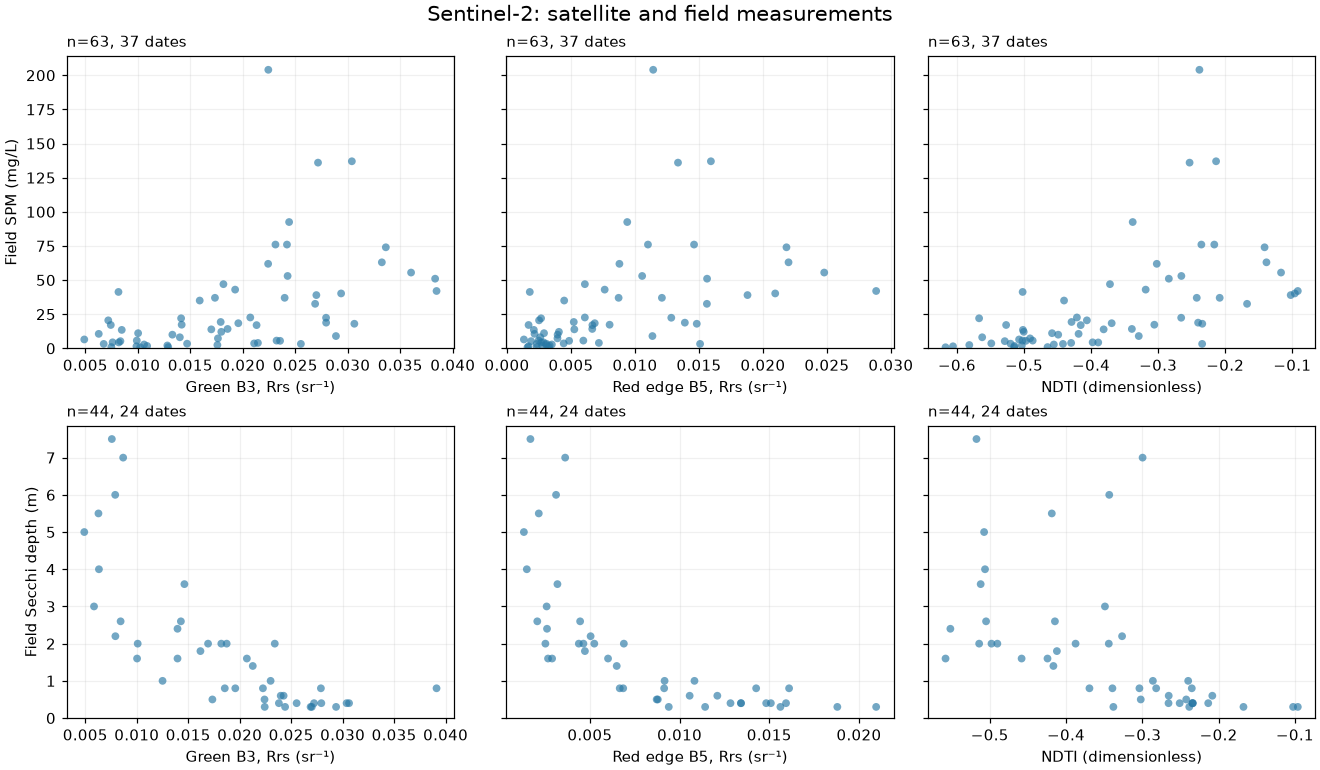

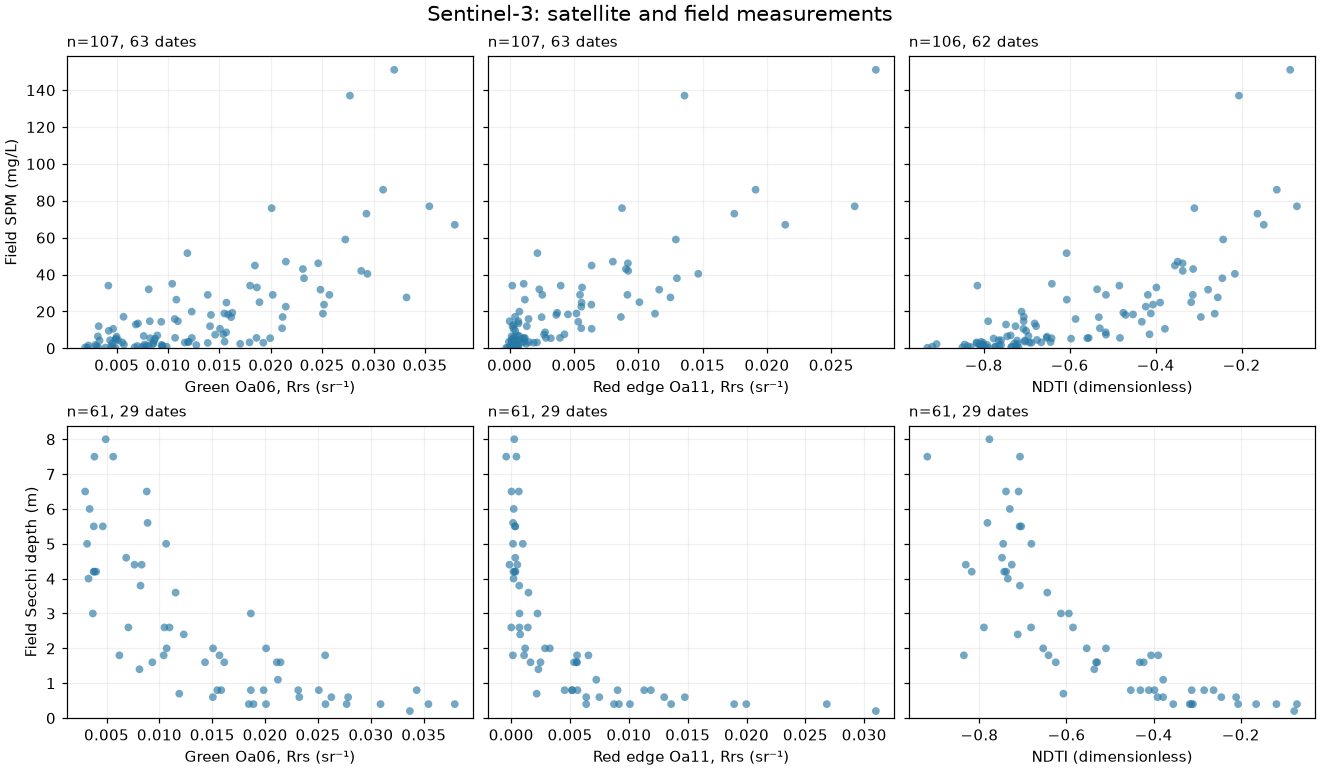

In [4]:
# A4: initial satellite–field comparisons at the reference stations
import numpy as np
import matplotlib.pyplot as plt

a4_roles = pd.read_csv(DATA / 'model_preparation/local_assignments.csv')
a4 = matchups.merge(a4_roles[['row_id', 'role']], on='row_id',
                    how='inner', validate='one_to_one')
a4 = a4.loc[a4['role'].eq('development')]
a4_bands = {
    'S2': [('raw__Rrs_B3', 'Green B3, Rrs (sr⁻¹)'),
           ('raw__Rrs_B5', 'Red edge B5, Rrs (sr⁻¹)'),
           ('raw__NDTI', 'NDTI (dimensionless)')],
    'S3': [('raw__Rrs_Oa06', 'Green Oa06, Rrs (sr⁻¹)'),
           ('raw__Rrs_Oa11', 'Red edge Oa11, Rrs (sr⁻¹)'),
           ('raw__NDTI', 'NDTI (dimensionless)')]
}
a4_out = PROJECT / 'figures/A4'
a4_out.mkdir(parents=True, exist_ok=True)

for sensor, features in a4_bands.items():
    fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharey='row', layout='constrained')
    for i, (target, label) in enumerate([('SPM', 'SPM (mg/L)'), ('Secchi', 'Secchi depth (m)')]):
        group = a4.loc[a4['sensor'].eq(sensor) & a4['target'].eq(target)]
        for ax, (feature, xlabel) in zip(axes[i], features):
            pairs = group[[feature, 'target_value', 'acquisition_date']].replace(
                [np.inf, -np.inf], np.nan).dropna()
            ax.scatter(pairs[feature], pairs['target_value'], s=26, alpha=.65,
                       color='#2878a5', edgecolors='none')
            ax.set_xlabel(xlabel)
            ax.set_title(f"n={len(pairs)}, {pairs['acquisition_date'].nunique()} dates",
                         loc='left', fontsize=10)
            ax.grid(alpha=.18)
            ax.set_axisbelow(True)
        axes[i, 0].set_ylabel('Field ' + label)
        axes[i, 0].set_ylim(bottom=0)
    fig.suptitle(f"Sentinel-{sensor[1]}: satellite and field measurements", fontsize=14)
    for suffix in ['png', 'svg']:
        fig.savefig(a4_out / f'{sensor}_initial_comparison.{suffix}', dpi=300)
    plt.show()


Higher reflectance or NDTI generally goes with higher SPM and shallower Secchi depth. S2 SPM is especially scattered at high concentrations. The sensors cover different samples, so these plots don't rank their accuracy.


## 2. GLORIA

[GLORIA](https://doi.pangaea.de/10.1594/PANGAEA.948492) pairs field reflectance spectra with water-quality measurements ([Lehmann et al., 2023](https://www.nature.com/articles/s41597-023-01973-y)). Join by GLORIA_ID. Total suspended solids (TSS) is the source label for SPM: g/m³ and mg/L are numerically equal, though lab methods may differ.

Here we use the measured spectra to simulate satellite bands. Section 11 instead pairs GLORIA samples with actual images. No missing values are filled.


In [31]:
# 2: read the original GLORIA files
meta = pd.read_csv(GLORIA / 'GLORIA_meta_and_lab.csv').dropna(how='all')
qc = pd.read_csv(GLORIA / 'GLORIA_qc_flags.csv').dropna(how='all')
spectra = pd.read_csv(GLORIA / 'GLORIA_Rrs.csv').dropna(how='all')

meta = meta.set_index('GLORIA_ID', verify_integrity=True)
qc = qc.set_index('GLORIA_ID', verify_integrity=True)
spectra = spectra.set_index('GLORIA_ID', verify_integrity=True)
assert set(meta.index) == set(qc.index) == set(spectra.index)

gloria = meta.join(qc, validate='one_to_one').join(spectra, validate='one_to_one')
gloria['waterbody_key'] = gloria['Country'].str.strip() + ' / ' + gloria['Site_name'].str.strip()
pd.Series({'joined observations': len(gloria), 'wavelengths': len(spectra.columns),
           'Flagged = 0': gloria['Flagged'].eq(0).sum(),
           'Flagged = 1': gloria['Flagged'].eq(1).sum()}, name='n')


/var/folders/2h/dqqlk7_13rx_lpyyjvlx_wxc0000gn/T/ipykernel_80179/1936466566.py:6: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  meta = meta.set_index('GLORIA_ID', verify_integrity=True)
/var/folders/2h/dqqlk7_13rx_lpyyjvlx_wxc0000gn/T/ipykernel_80179/1936466566.py:7: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  qc = qc.set_index('GLORIA_ID', verify_integrity=True)
/var/folders/2h/dqqlk7_13rx_lpyyjvlx_wxc0000gn/T/ipykernel_80179/1936466566.py:8: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  spectra = spectra.set_index('GLORIA_ID', verify_integrity=True)
/var/folders/2h/dqqlk7_13rx_lpyyjvlx_wxc0000

joined observations    7572
wavelengths             551
Flagged = 0            5793
Flagged = 1            1779
Name: n, dtype: int64

### Quality selection

Keep estuaries and coastal ocean (Water_body_type 2 and 3), with separate positive TSS and Secchi lists.

- Require Baseline_shift, QWIP_fail and Suspect all to be zero. An unassessed flag does not pass.
- Blue/UV noise, the oxygen artefact and noise at 750–900 nm are warnings for our main bands (roughly 522–736 nm). Optional near-infrared needs Noisy_red = 0.
- Flagged is a combined indicator. We use it for comparison only.

QWIP checks the shape of the spectrum and can also flag unusual real spectra. Flag counts overlap. [Flag code](https://github.com/dmaciel123/gloria_flags) · [QWIP paper](https://doi.org/10.3389/frsen.2022.869611).


In [32]:
# 2: inspect each flag before choosing the exclusion list
coastal = gloria.loc[gloria['Water_body_type'].isin([2, 3])].copy()
flag_counts = pd.DataFrame({
    'SPM flagged': coastal.loc[coastal['TSS'].gt(0), qc.columns].eq(1).sum(),
    'Secchi flagged': coastal.loc[coastal['Secchi_depth'].gt(0), qc.columns].eq(1).sum(),
    'SPM unknown': coastal.loc[coastal['TSS'].gt(0), qc.columns].isna().sum(),
    'Secchi unknown': coastal.loc[coastal['Secchi_depth'].gt(0), qc.columns].isna().sum()
})
flag_counts


,SPM flagged,Secchi flagged,SPM unknown,Secchi unknown
Noisy_red,2,8,672,393
Noisy_blue,6,0,563,435
Baseline_shift,22,13,0,0
Oxygen_signal,90,46,0,0
Negative_uv_slope,24,0,565,435
QWIP_fail,33,19,0,0
Suspect,39,21,0,0
Flagged,178,80,0,0


In [33]:
# 2: apply the explicit working rule, keeping the original data
reject_flags = ['Baseline_shift', 'Suspect', 'QWIP_fail']
quality_ok = pd.Series(True, index=coastal.index)
labels = ['TSS', 'Secchi_depth']
selection = {'Coastal + positive label': [coastal[col].gt(0).sum() for col in labels]}

for flag in reject_flags:
    quality_ok &= coastal[flag].eq(0)
    selection['After ' + flag] = [
        (quality_ok & coastal[col].gt(0)).sum() for col in labels
    ]

gloria_spm = coastal.loc[quality_ok & coastal['TSS'].gt(0)].copy()
gloria_secchi = coastal.loc[quality_ok & coastal['Secchi_depth'].gt(0)].copy()
selection['Comparison: old Flagged = 0'] = [
    (coastal['Flagged'].eq(0) & coastal[col].gt(0)).sum() for col in labels
]
pd.DataFrame(selection, index=['SPM', 'Secchi']).T


,SPM,Secchi
Coastal + positive label,1335,480
After Baseline_shift,1313,467
After Suspect,1275,450
After QWIP_fail,1255,436
Comparison: old Flagged = 0,1157,400


In [34]:
# 2: selected candidates by reported water-body type
waterbodies = {2: 'Estuary', 3: 'Coastal ocean'}
by_waterbody = pd.DataFrame({
    'SPM': gloria_spm.groupby('Water_body_type').size(),
    'Secchi': gloria_secchi.groupby('Water_body_type').size()
}).rename(index=waterbodies)
by_waterbody.index.name = 'water body'
by_waterbody


,SPM,Secchi
water body,,
Estuary,265,209
Coastal ocean,990,227


### Wavelength coverage

These are counts at individual wavelengths. A simulated band needs the whole range it responds to. The 865 nm column is an optional near-infrared check.


In [35]:
# 2: inspect available reflectance at selected wavelengths
coverage = pd.DataFrame({
    'TSS / SPM': gloria_spm[spectra.columns].notna().sum(),
    'Secchi': gloria_secchi[spectra.columns].notna().sum()
})
coverage.loc[[f'Rrs_{w}' for w in [443, 490, 560, 665, 705, 709, 865]]]


,TSS / SPM,Secchi
Rrs_443,1255,436
Rrs_490,1255,436
Rrs_560,1255,436
Rrs_665,1255,436
Rrs_705,1192,436
Rrs_709,1192,436
Rrs_865,631,81


## 3. Sensor-band conversion

Average each spectrum using the sensor response as weights. A satellite band covers a range of wavelengths, so reading just the centre would miss part of the signal.

$$R_{rs,b} \approx \frac{\sum_\lambda R_{rs}(\lambda)\,S_b(\lambda)}{\sum_\lambda S_b(\lambda)}$$

Use separate responses for S2A/B/C and S3A/B. Interpolate the response onto the 1 nm grid, not the measured spectrum. A missing wavelength with positive weight makes that band unavailable. This approximates the satellite bands without separately integrating radiance and irradiance or correcting viewing differences.

[Pahlevan et al.](https://doi.org/10.1016/j.rse.2021.112860) · [ACOLITE implementation](https://github.com/acolite/acolite/blob/main/acolite/shared/rsr_convolute_dict.py) · [GLORIA example](https://doi.org/10.3389/frsen.2024.1383147) · [Approximation limits](https://doi.org/10.1364/OE.391470) · [Response files](data/srf_manifest.json).


In [36]:
# 3: align responses and average each spectrum over the full band
import numpy as np

rsr_data = pd.read_csv(DATA / 'spectral_response_samples.csv')
wavelengths = spectra.columns.str.removeprefix('Rrs_').astype(int).to_numpy()
simulated, responses = {}, {}

for (platform, band), curve in rsr_data.groupby(['platform', 'band'], sort=False):
    shifted = curve['wavelength_nm'] + curve['shift_nm']
    assert shifted.between(wavelengths.min(), wavelengths.max()).all()
    # Interpolate the response only. Missing reflectance stays missing.
    response = np.interp(wavelengths, shifted, curve['response'], left=0, right=0)
    responses[platform + '_' + band] = response
    use = response > 0
    weights = response[use] / response[use].sum()
    if platform not in simulated:
        simulated[platform] = pd.DataFrame(index=spectra.index)
    simulated[platform][band] = spectra.loc[:, use].to_numpy() @ weights

responses = pd.DataFrame(responses, index=wavelengths)
band_counts = []
for platform, frame in simulated.items():
    band_counts.append([platform,
                        frame.reindex(gloria_spm.index).dropna().shape[0],
                        frame.reindex(gloria_secchi.index).dropna().shape[0]])
pd.DataFrame(band_counts, columns=['platform', 'SPM: all 3 bands', 'Secchi: all 3 bands'])


,platform,SPM: all 3 bands,Secchi: all 3 bands
0,S2A,1192,436
1,S2B,1192,436
2,S2C,1191,436
3,S3A,1192,436
4,S3B,1192,436


### Band indices

Keep the bands and add five inputs. With G, R and E for green, red and red edge: NDTI = (R − G)/(R + G), then R/G, E/R, E/G and (E − R)/(E + R). Each required band must exceed 10⁻⁶ sr⁻¹. NDTI and positive R/G order observations the same way.


In [37]:
# 3: keep the band-only tables and make copies with indices
simulated_with_indices = {platform: frame.copy() for platform, frame in simulated.items()}

for platform, frame in simulated_with_indices.items():
    core = ['B3', 'B4', 'B5'] if platform.startswith('S2') else ['Oa06', 'Oa08', 'Oa11']
    green, red, red_edge = (frame[col].where(frame[col].gt(1e-6)) for col in core)
    frame['NDTI'] = (red - green) / (red + green)
    frame['red_green'] = red / green
    frame['red_edge_red'] = red_edge / red
    frame['red_edge_green'] = red_edge / green
    frame['ND_rededge_red'] = (red_edge - red) / (red_edge + red)

simulated_with_indices['S2A'].head().round(5)


,B3,B4,B5,NDTI,red_green,red_edge_red,red_edge_green,ND_rededge_red
GLORIA_ID,,,,,,,,
GID_1,0.00316,0.00246,0.00217,-0.12543,0.77710,0.88376,0.68676,-0.06171
GID_2,0.00338,0.00259,0.00229,-0.13278,0.76557,0.88442,0.67708,-0.06134
GID_3,0.00372,0.00288,0.00259,-0.12678,0.77497,0.90017,0.69761,-0.05254
GID_4,0.00403,0.00386,0.00366,-0.02210,0.95675,0.94922,0.90817,-0.02605
GID_5,0.00422,0.00393,0.00419,-0.03527,0.93186,1.06608,0.99343,0.03198


### Earlier optional retrievals

We tried near-infrared (about 865 nm), [Nechad SPM](https://doi.org/10.1016/j.rse.2009.11.022) and [Dogliotti turbidity](https://doi.org/10.1016/j.rse.2014.09.020) for exploration. Both formulas use water reflectance π times remote-sensing reflectance. Dogliotti uses nearby red and near-infrared bands without recalibration. Its output is in FNU, not mg/L.

Nechad's validity limit would drop some high-red observations if we required it as an input. We left all three optional inputs out of the models. The table counts available estimates, not accurate ones. [Formula details](data/satellite_audit/feature_registry.csv).


In [38]:
# 3: optional fixed retrievals, kept separate from the core features
nir_rsr = pd.read_csv(DATA / 'nir_response_samples.csv')
retrievals, retrieval_counts = {}, []

for platform, frame in simulated.items():
    curve = nir_rsr.loc[nir_rsr['platform'].eq(platform)]
    shifted = curve['wavelength_nm'] + curve['shift_nm']
    assert shifted.between(wavelengths.min(), wavelengths.max()).all()
    response = np.interp(wavelengths, shifted, curve['response'], left=0, right=0)
    use = response > 0
    nir = pd.Series(spectra.loc[:, use].to_numpy() @ (response[use] / response[use].sum()),
                    index=spectra.index)
    nir = nir.where(qc['Noisy_red'].eq(0))
    red_band = 'B4' if platform.startswith('S2') else 'Oa08'
    rho_red, rho_nir = np.pi * frame[red_band], np.pi * nir

    # Nechad: same 665 nm coefficients and 0.5 C limit as the satellite audit.
    rho = rho_red.where(rho_red.ge(0) & rho_red.lt(0.5 * 0.1728))
    nechad = 355.85 * rho / (1 - rho / 0.1728)

    # Dogliotti: require both inputs, then evaluate only active branches.
    valid = (np.isfinite(rho_red) & np.isfinite(rho_nir)
             & rho_red.ge(0) & rho_nir.ge(0))
    red, nir_rho = rho_red.where(valid), rho_nir.where(valid)
    weight = ((red - 0.05) / 0.02).clip(0, 1)
    r = red.where(weight.lt(1) & red.lt(0.1641))
    n = nir_rho.where(weight.gt(0) & nir_rho.lt(0.2112)
                      & (1 - nir_rho / 0.2112).abs().gt(1e-8))
    t_red = 228.1 * r / (1 - r / 0.1641)
    t_nir = 3078.9 * n / (1 - n / 0.2112)
    dogliotti = pd.Series(np.nan, index=frame.index)
    dogliotti.loc[weight.eq(0)] = t_red
    dogliotti.loc[weight.eq(1)] = t_nir
    blend = weight.gt(0) & weight.lt(1)
    dogliotti.loc[blend] = ((1 - weight) * t_red + weight * t_nir).loc[blend]

    retrievals[platform] = pd.DataFrame({
        curve['band'].iloc[0]: nir,
        'Nechad2010_ACOLITE_form': nechad,
        'Dogliotti2015_nearest_available': dogliotti
    })
    retrieval_counts.append([platform,
        nechad.reindex(gloria_spm.index).notna().sum(),
        nechad.reindex(gloria_secchi.index).notna().sum(),
        dogliotti.reindex(gloria_spm.index).notna().sum(),
        dogliotti.reindex(gloria_secchi.index).notna().sum()])

pd.DataFrame(retrieval_counts, columns=[
    'platform', 'Nechad: SPM', 'Nechad: Secchi', 'Dogliotti: SPM', 'Dogliotti: Secchi'
])


,platform,Nechad: SPM,Nechad: Secchi,Dogliotti: SPM,Dogliotti: Secchi
0,S2A,1149,423,625,73
1,S2B,1149,423,625,73
2,S2C,1087,423,625,73
3,S3A,1150,423,625,73
4,S3B,1150,423,625,73


### Model input candidates

Eight candidate inputs: three bands and five indices. The targets are still field SPM and Secchi depth. Check availability in Section 6.


In [39]:
# 3: non-NIR input candidates, with all original rows retained
candidate_inputs = {
    platform: frame.copy()
    for platform, frame in simulated_with_indices.items()
}
pd.DataFrame({'S2': candidate_inputs['S2A'].columns,
              'S3': candidate_inputs['S3A'].columns})


,S2,S3
0,B3,Oa06
1,B4,Oa08
2,B5,Oa11
3,NDTI,NDTI
4,red_green,red_green
5,red_edge_red,red_edge_red
6,red_edge_green,red_edge_green
7,ND_rededge_red,ND_rededge_red


## 4. Inspect spectra

Check six spectra across clean, warning and rejected cases. We picked examples using flags and spectral shape, without looking at SPM or Secchi. Shading shows the S2A band ranges. Dots show the weighted means. The panels use different vertical scales.


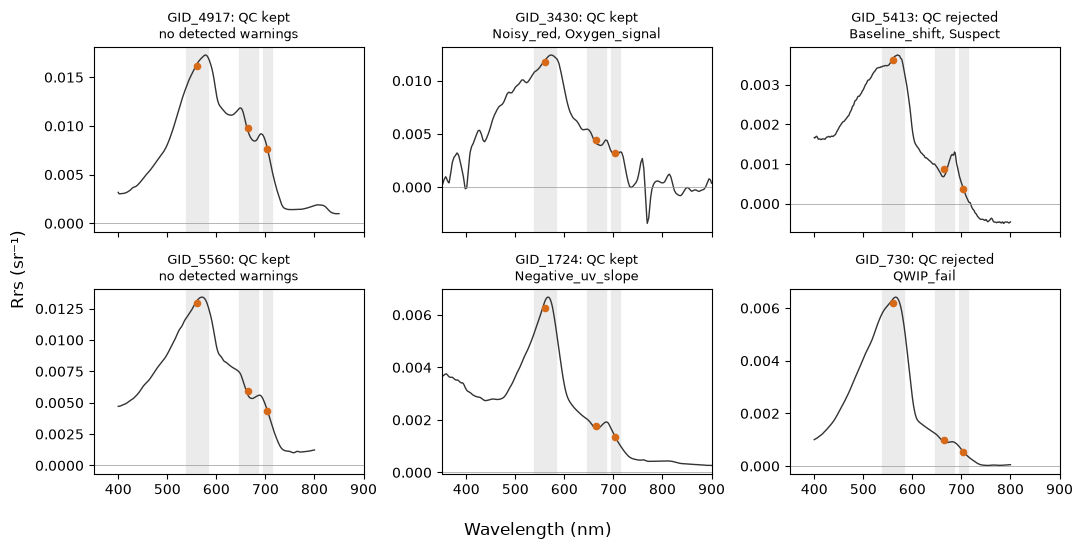

In [40]:
# 4: manual inspection, two examples per column
import matplotlib.pyplot as plt

example_ids = ['GID_4917', 'GID_3430', 'GID_5413',
               'GID_5560', 'GID_1724', 'GID_730']
wavelengths = spectra.columns.str.removeprefix('Rrs_').astype(int)
s2a = responses.filter(like='S2A_')
centres = s2a.mul(s2a.index, axis=0).sum() / s2a.sum()
fig, axes = plt.subplots(2, 3, figsize=(11, 5.5), sharex=True)

for ax, gid in zip(axes.flat, example_ids):
    ax.plot(wavelengths, spectra.loc[gid], color='0.2', linewidth=1)
    for name in s2a:
        support = s2a.index[s2a[name].gt(0)]
        ax.axvspan(support.min(), support.max(), color='0.92', zorder=0)
    ax.scatter(centres, simulated['S2A'].loc[gid], color='#d76a19', s=20, zorder=3)
    issues = qc.loc[gid].drop('Flagged')
    warnings = ', '.join(issues.index[issues.eq(1)]) or 'no detected warnings'
    status = 'QC kept' if quality_ok.loc[gid] else 'QC rejected'
    ax.set_title(f'{gid}: {status}\n{warnings}', fontsize=9)
    ax.axhline(0, color='0.6', linewidth=0.5)
    ax.set_xlim(350, 900)

fig.supxlabel('Wavelength (nm)')
fig.supylabel('Rrs (sr⁻¹)')
fig.tight_layout()
plt.show()


## 5. Pretraining plan

Start a small fully connected network on GLORIA spectra, then update it on local satellite–field pairs. Compare with learning from local data from scratch. We prepared four datasets, but ran the neural experiment only for S2-SPM.

- Eight inputs, two hidden layers (15–15 or 32–16) and one output. The smaller size was inspired by [Niroumand-Jadidi & Bovolo](https://doi.org/10.5194/isprs-annals-V-3-2022-339-2022).
- Compare log₁₀ and square-root SPM targets. The log compresses peaks more. Choose settings by log₁₀-RMSE after converting predictions back to concentrations.
- Scale using GLORIA training medians and interquartile ranges. Use the same scaling for the local neural comparisons.
- Adam, learning rate 0.001, weight decay 0.0001, batches of 32. Train up to 300 epochs, stopping after 30 without improvement and restoring the best weights.

Log error compares misses by factor. RMSE in mg/L gives big concentration misses more weight, MAE is the average size of a miss, and negative bias means underestimation. [Metric definitions](https://scikit-learn.org/1.7/modules/model_evaluation.html#regression-metrics).

[Zhao](https://doi.org/10.1016/j.jag.2026.105294) and [Gaur](https://doi.org/10.1007/s11783-025-1930-x) motivate transfer. [Saranathan](https://doi.org/10.3389/frsen.2024.1383147) motivates simulated bands, scaling and log targets. The settings here are ours. We didn't add noise or inland waters.


## 6. Splits and usable inputs

GLORIA: group nearby sites within 25 km, including chains and the listed Chesapeake tributaries. Shuffle the 35 groups with seed 42: 25 train, five validation, five test. Keep versions of the same spectrum together.

Local: reserve about 20% of acquisition dates (seed 42). On the other dates, train on two groups and predict the third, then rotate. For choices like SVR settings or regression formulas, do a smaller round of checks inside the training dates first. That's what inner and outer folds mean in the code. [Grouped validation](https://scikit-learn.org/1.7/modules/cross_validation.html#group-k-fold) · [Roberts et al.](https://doi.org/10.1111/ecog.02881).

These are checks on other dates in our region. The early correlations and later viewing of the S2 test limit how blind the final evaluation is.


In [41]:
# 6: group nearby reported sites without removing observations
PREP = DATA / 'model_preparation'
PREP.mkdir(exist_ok=True)

def save_fixed(frame, filename):
    path = PREP / filename
    contents = frame.to_csv(index=False)
    if path.exists():
        assert path.read_text() == contents, f'{filename} changed. Review before replacing.'
    else:
        frame.to_csv(path, index=False)

eligible_ids = gloria_spm.index.union(gloria_secchi.index).sort_values()
geography = gloria.loc[eligible_ids, ['waterbody_key', 'Latitude', 'Longitude']].copy()
codes, site_names = pd.factorize(geography['waterbody_key'], sort=True)
lat, lon = np.deg2rad(geography[['Latitude', 'Longitude']].to_numpy()).T
h = (np.sin((lat[:, None] - lat)/2)**2
     + np.cos(lat[:, None])*np.cos(lat)*np.sin((lon[:, None] - lon)/2)**2)
distance = 12742*np.arcsin(np.sqrt(np.clip(h, 0, 1)))
i, j = np.where(np.triu(distance <= 25, 1) & (codes[:, None] != codes))
links = pd.DataFrame({'site_a': site_names[codes[i]], 'site_b': site_names[codes[j]],
                      'distance_km': distance[i, j]})
links = links.groupby(['site_a', 'site_b'], as_index=False)['distance_km'].min()

# Named tributaries are kept with their parent bay even beyond 25 km.
chesapeake = ['Chesapeake Bay, MD', 'Baltimore Harbor, MD', 'Monie Bay, MD',
              'Otter Point Creek, MD', 'St. Leonard Creek, MD']
bay_sites = geography.loc[gloria.loc[eligible_ids, 'Site_name'].isin(chesapeake),
                         'waterbody_key'].unique()
extra = pd.DataFrame({'site_a': bay_sites[0], 'site_b': bay_sites[1:],
                      'distance_km': np.nan})
edges = pd.concat([links.assign(reason='within 25 km'),
                   extra.assign(reason='named Chesapeake tributary')], ignore_index=True)
group = {site: site for site in site_names}
for a, b in edges[['site_a', 'site_b']].itertuples(index=False, name=None):
    old, new = group[b], group[a]
    group = {site: new if value == old else value for site, value in group.items()}
geography['geographic_group'] = geography['waterbody_key'].map(group)
save_fixed(edges, 'geographic_links.csv')
save_fixed(geography.reset_index(), 'geographic_groups.csv')
pd.Series({'observations': len(geography), 'reported sites': len(site_names),
           'geographic groups': geography['geographic_group'].nunique(),
           'missing coordinates, retained in reported site': geography['Latitude'].isna().sum()})


observations                                      1398
reported sites                                      86
geographic groups                                   35
missing coordinates, retained in reported site      34
dtype: int64

In [42]:
# 6: freeze GLORIA groups before checking feature availability
groups = np.sort(geography['geographic_group'].unique())
order = np.random.default_rng(42).permutation(groups)
n_test = round(0.15*len(order))
n_val = round(0.15*len(order))
roles = dict.fromkeys(order, 'train')
roles.update(dict.fromkeys(order[:n_test], 'test'))
roles.update(dict.fromkeys(order[n_test:n_test+n_val], 'validation'))
source_roles = geography[['waterbody_key', 'geographic_group']].copy()
source_roles['role'] = source_roles['geographic_group'].map(roles)
source_roles['SPM_eligible'] = source_roles.index.isin(gloria_spm.index)
source_roles['Secchi_eligible'] = source_roles.index.isin(gloria_secchi.index)
save_fixed(source_roles.reset_index(), 'gloria_assignments.csv')
assert source_roles.groupby('geographic_group')['role'].nunique().eq(1).all()
source_roles.groupby('role').agg(groups=('geographic_group', 'nunique'),
    SPM=('SPM_eligible', 'sum'), Secchi=('Secchi_eligible', 'sum')).reindex(
    ['train', 'validation', 'test'])


,groups,SPM,Secchi
role,,,
train,25,1068,330
validation,5,105,32
test,5,82,74


In [43]:
# 6: reserve whole local dates across sensors and targets
local = matchups.loc[matchups['sensor'].eq('S2') | matchups['collection'].eq('003')].copy()
assert local.groupby('sample_id')['acquisition_date'].nunique().eq(1).all()
assert local.groupby('product_id')['acquisition_date'].nunique().eq(1).all()
dates = np.sort(local['acquisition_date'].unique())
test_dates = np.random.default_rng(42).permutation(dates)[:int(np.ceil(0.2*len(dates)))]
local['role'] = np.where(local['acquisition_date'].isin(test_dates), 'test', 'development')
local['platform'] = local['product_name'].str[:3]
local_roles = local[['row_id', 'sample_id', 'sensor', 'collection', 'target', 'platform',
                     'acquisition_date', 'product_id', 'role']].sort_values('row_id')
save_fixed(local_roles, 'local_assignments.csv')
assert local.groupby('acquisition_date')['role'].nunique().eq(1).all()
local.groupby(['sensor', 'target', 'role']).agg(
    observations=('sample_id', 'nunique'), dates=('acquisition_date', 'nunique'))


observations  dates
sensor target role                            
S2     SPM    development            63     37
              test                   17      9
       Secchi development            44     24
              test                    8      4
S3     SPM    development           107     63
              test                   27     15
       Secchi development            61     29
              test                   18     10

Keep inputs available in at least 75% of GLORIA training rows (each platform) and local development rows, per sensor and target. This check uses no test rows or target values. We do it once, before the date rounds.

For fitting, keep only rows with all selected inputs. Platform versions don't count as new independent observations.


In [44]:
# 6: apply the agreed gate without using validation or test rows
index_columns = {'NDTI': 'NDTI', 'red_green': 'red_green_ratio',
    'red_edge_red': 'rededge_red_ratio', 'red_edge_green': 'rededge_green_ratio',
    'ND_rededge_red': 'ND_rededge_red'}
local_inputs, selected_inputs, availability_rows = {}, {}, []

for sensor in ['S2', 'S3']:
    platforms = [p for p in candidate_inputs if p.startswith(sensor)]
    columns = candidate_inputs[platforms[0]].columns.tolist()
    raw_columns = ['raw__' + index_columns.get(c, 'Rrs_' + c) for c in columns]
    for target, pool in [('SPM', gloria_spm), ('Secchi', gloria_secchi)]:
        source_ids = pool.index.intersection(source_roles.index[source_roles['role'].eq('train')])
        part = local.loc[local['sensor'].eq(sensor) & local['target'].eq(target)]
        values = part[raw_columns].copy().replace([np.inf, -np.inf], np.nan)
        values.columns = columns
        local_inputs[sensor, target] = values
        source_counts = pd.DataFrame({p: np.isfinite(candidate_inputs[p].loc[source_ids]).sum()
                                      for p in platforms})
        dev = values.loc[part.index[part['role'].eq('development')]]
        source_fraction = source_counts.min(axis=1)/len(source_ids)
        local_fraction = dev.notna().mean()
        keep = source_fraction.ge(0.75) & local_fraction.ge(0.75)
        selected_inputs[sensor, target] = keep.index[keep].tolist()
        for feature in columns:
            availability_rows.append([sensor, target, feature, len(source_ids),
                int(source_counts.loc[feature].min()), len(dev), int(dev[feature].notna().sum()),
                source_fraction[feature], local_fraction[feature], bool(keep[feature])])

availability = pd.DataFrame(availability_rows, columns=['sensor', 'target', 'feature',
    'GLORIA_train_n', 'GLORIA_min_platform_available_n', 'local_dev_n', 'local_available_n',
    'GLORIA_fraction', 'local_fraction', 'keep'])
save_fixed(availability, 'feature_availability_no_nechad.csv')
availability.groupby(['sensor', 'target']).agg(
    candidates=('feature', 'size'), retained=('keep', 'sum'),
    GLORIA_min_fraction=('GLORIA_fraction', 'min'),
    local_min_fraction=('local_fraction', 'min')).round(3)


candidates  retained  GLORIA_min_fraction  local_min_fraction
sensor target                                                               
S2     SPM              8         8                0.940               1.000
       Secchi           8         8                1.000               1.000
S3     SPM              8         8                0.941               0.972
       Secchi           8         8                1.000               0.967

In [45]:
# 6: show joint completeness, without selecting or imputing rows
count_rows = []
for (sensor, target), features in selected_inputs.items():
    assert features, f'No features passed for {sensor}, {target}'
    pool = gloria_spm if target == 'SPM' else gloria_secchi
    for platform, frame in candidate_inputs.items():
        if not platform.startswith(sensor):
            continue
        for role in ['train', 'validation', 'test']:
            ids = pool.index.intersection(source_roles.index[source_roles['role'].eq(role)])
            complete = np.isfinite(frame.loc[ids, features]).all(axis=1)
            count_rows.append(['GLORIA', platform, target, role, len(ids), int(complete.sum())])
    part = local.loc[local['sensor'].eq(sensor) & local['target'].eq(target)]
    for role in ['development', 'test']:
        ids = part.index[part['role'].eq(role)]
        complete = local_inputs[sensor, target].loc[ids, features].notna().all(axis=1)
        count_rows.append(['local', sensor, target, role, len(ids), int(complete.sum())])

complete_counts = pd.DataFrame(count_rows, columns=[
    'dataset', 'sensor_platform', 'target', 'role', 'eligible', 'all_inputs_present'])
complete_counts['incomplete'] = complete_counts['eligible'] - complete_counts['all_inputs_present']
save_fixed(complete_counts, 'complete_input_counts_no_nechad.csv')
complete_counts.assign(sensor=complete_counts['sensor_platform'].str[:2]).groupby(
    ['dataset', 'sensor', 'target', 'role']).agg(
    eligible=('eligible', 'first'), all_inputs_present=('all_inputs_present', 'min'),
    incomplete=('incomplete', 'max'))


eligible  all_inputs_present  incomplete
dataset sensor target role                                                 
GLORIA  S2     SPM    test               82                  82           0
                      train            1068                1004          64
                      validation        105                 105           0
               Secchi test               74                  74           0
                      train             330                 330           0
                      validation         32                  32           0
        S3     SPM    test               82                  82           0
                      train            1068                1005          63
                      validation        105                 105           0
               Secchi test               74                  74           0
                      train             330                 330           0
                      validation         32                  32           0
local   S2     SPM    development        63                  63           0
                      test               17                  17           0
               Secchi development        44                  44           0
                      test                8                   8           0
        S3     SPM    development       107                 104           3
                      test               27                  24           3
               Secchi development        61                  59           2
                      test               18                  17           1

All eight inputs pass. Some rows still lack full band coverage or have ratios we can't calculate. Removing Nechad keeps otherwise usable high-red rows. Secchi has few validation groups, and the local S2 test has just eight samples from four dates. We didn't train a Secchi network.


## 7. Optional S2-SPM benchmark: MDN

Run the published [MDN-STREAM MSI model](https://github.com/STREAM-RS/MDN-STREAM/tree/79d1b47a992d25b134bdfe4d10fe7f4e7e30e6d1/Weights/MSI) on local S2-SPM development observations. It uses B1–B7 and its own scaling. The reader needs h5py and takes the median across ten published model runs. No local training or test predictions. We haven't checked overlap with its original training data.


In [48]:
# 7: frozen MDN predictions on S2-SPM development observations only
%pip install h5py==3.14.0
%pip install mdn_msi --quiet
from mdn_msi import predict_tss

mdn_bands = ['raw__Rrs_B' + str(i) for i in range(1, 8)]
mdn_dev = local.loc[local['sensor'].eq('S2') & local['target'].eq('SPM')
                    & local['role'].eq('development')].copy()
assert mdn_dev[[b + '__n' for b in mdn_bands]].ge(20).all().all()
mdn_dev['MDN_TSS_mg_l'] = predict_tss(mdn_dev[mdn_bands].to_numpy(), DATA / 'mdn_msi')
observed, predicted = mdn_dev['target_value'], mdn_dev['MDN_TSS_mg_l']
error = predicted - observed
pd.Series({'observations': len(mdn_dev), 'dates': mdn_dev['acquisition_date'].nunique(),
    'MAE (mg/L)': error.abs().mean(), 'RMSE (mg/L)': np.sqrt((error**2).mean()),
    'R2': 1 - (error**2).sum()/((observed-observed.mean())**2).sum(),
    'log10 RMSE': np.sqrt(((np.log10(predicted)-np.log10(observed))**2).mean())
}, name='Frozen MDN, development').round(3)


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for h5py: filename=h5py-3.14.0-cp314-cp314-macosx_26_0_arm64.whl size=1690543 sha256=d5c7be92d4f770e3844a8fba3a5a492b30f900f3e20e1b0c46440bd9a5c8f9dd
  Stored in directory: /Users/ehol/Library/Caches/pip/wheels/8a/03/84/e7413999b20eb30afbece8f215b38bb47b1f27ae219584eaf8
Successfully built h5py

[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
ERROR: Could not find a version that satisfies the requirement mdn_msi (from versions: none)

[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
ERROR: No matching distribution found for mdn_msi
Note: you may need to restart the kernel to use updated packages.


observations    63.000
dates           37.000
MAE (mg/L)      21.220
RMSE (mg/L)     39.682
R2              -0.141
log10 RMSE       0.575
Name: Frozen MDN, development, dtype: float64

Development R² was −0.141: worse than predicting the mean of these measurements. This is the published model as-is.


## 8. First run: S2-SPM pretraining

Try both network sizes and both target transforms on simulated S2 bands from GLORIA. Each original spectrum has total weight one across its usable S2A/B/C versions. Fit scaling on training spectra only.

Keep the best validation checkpoint by log₁₀-RMSE. An invalid prediction rules out that epoch. Run on CPU with PyTorch 2.9.1 and NumPy ≥2. Save results to RUN. No local or reserved GLORIA test predictions here.


In [24]:
# 8: assemble training and validation only
import torch

features = selected_inputs['S2', 'SPM']
source_ids = gloria_spm.index.intersection(
    source_roles.index[source_roles['role'].isin(['train', 'validation'])])
source = pd.concat([
    frame.loc[source_ids, features].assign(GLORIA_ID=source_ids, platform=platform)
    for platform, frame in candidate_inputs.items() if platform.startswith('S2')
], ignore_index=True)
source = source.join(source_roles[['role', 'geographic_group']], on='GLORIA_ID')
source = source.join(gloria_spm[['TSS']], on='GLORIA_ID')
source = source.loc[np.isfinite(source[features]).all(axis=1)].copy()
source['weight'] = 1/source.groupby('GLORIA_ID')['platform'].transform('size')
train = source.loc[source['role'].eq('train')].reset_index(drop=True)
valid = source.loc[source['role'].eq('validation')].reset_index(drop=True)
assert not set(train['GLORIA_ID']) & set(valid['GLORIA_ID'])
assert not set(train['geographic_group']) & set(valid['geographic_group'])
assert np.allclose(source.groupby('GLORIA_ID')['weight'].sum(), 1)
source.groupby('role').agg(observations=('GLORIA_ID', 'nunique'),
    platform_versions=('GLORIA_ID', 'size'), groups=('geographic_group', 'nunique'))


,observations,platform_versions,groups
role,,,
train,1005,3014,23
validation,105,315,5


In [25]:
# 8: weighted quantiles give each original observation equal influence
q25, centre, q75 = np.quantile(train[features].to_numpy(), [0.25, 0.5, 0.75],
    axis=0, weights=train['weight'].to_numpy(), method='inverted_cdf')
spread = np.where(q75 > q25, q75-q25, 1)
x_train = torch.tensor((train[features].to_numpy()-centre)/spread, dtype=torch.float32)
x_valid = torch.tensor((valid[features].to_numpy()-centre)/spread, dtype=torch.float32)
y_train = torch.tensor(train['TSS'].to_numpy(), dtype=torch.float32)
w_train = torch.tensor((train['weight']/train['weight'].mean()).to_numpy(), dtype=torch.float32)
y_valid = valid['TSS'].to_numpy()
w_valid = valid['weight'].to_numpy()
pd.DataFrame({'median': centre, 'IQR': spread}, index=features).round(5)


,median,IQR
B3,0.01550,0.01630
B4,0.00708,0.01348
B5,0.00513,0.01253
NDTI,-0.36336,0.40789
red_green,0.46696,0.45603
red_edge_red,0.71659,0.25612
red_edge_green,0.32994,0.52558
ND_rededge_red,-0.16510,0.17013


In [26]:
# 8: same optimiser and batch order for each candidate
import copy

torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)

def invert_target(z, transform):
    with np.errstate(over='ignore', invalid='ignore'):
        return 10.0**z if transform == 'log10' else np.where(z >= 0, z*z, np.nan)

def pretrain(hidden, transform):
    torch.manual_seed(42)
    model = torch.nn.Sequential(torch.nn.Linear(len(features), hidden[0]), torch.nn.ReLU(),
        torch.nn.Linear(hidden[0], hidden[1]), torch.nn.ReLU(), torch.nn.Linear(hidden[1], 1))
    optimiser = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=0.0001)
    target = torch.log10(y_train) if transform == 'log10' else torch.sqrt(y_train)
    generator = torch.Generator().manual_seed(42)
    best, best_state, best_epoch, stale = np.inf, None, None, 0
    history = []
    for epoch in range(1, 301):
        model.train()
        for batch in torch.randperm(len(train), generator=generator).split(32):
            optimiser.zero_grad()
            error = model(x_train[batch]).squeeze(1)-target[batch]
            loss = (w_train[batch]*error.square()).mean()
            loss.backward()
            optimiser.step()
        model.eval()
        with torch.no_grad():
            train_mse = (w_train*(model(x_train).squeeze(1)-target).square()).mean().item()
            z = model(x_valid).squeeze(1).numpy().astype(float)
        predicted = invert_target(z, transform)
        invalid = int((~np.isfinite(predicted) | (predicted <= 0)).sum())
        score = np.inf if invalid else np.sqrt(np.average(
            (np.log10(predicted)-np.log10(y_valid))**2, weights=w_valid))
        history.append([epoch, train_mse, score, invalid])
        if score < best:
            best, best_state, best_epoch, stale = score, copy.deepcopy(model.state_dict()), epoch, 0
        else:
            stale += 1
        if stale >= 30:
            break
    if best_state is not None:
        model.load_state_dict(best_state)
    return model, pd.DataFrame(history, columns=[
        'epoch', 'training_transformed_MSE', 'validation_log10_RMSE', 'invalid_validation_predictions'
    ]), best_epoch


In [27]:
# 8: save every comparison, select by validation only
RUN = PROJECT / 'models/S2_SPM/pretrain_01'
assert not RUN.exists(), 'Use a new RUN folder to preserve earlier comparisons.'
RUN.mkdir(parents=True)
records, histories, validation_predictions = [], [], []
for hidden in [(15, 15), (32, 16)]:
    for transform in ['log10', 'sqrt']:
        name = f'{hidden[0]}_{hidden[1]}_{transform}'
        model, history, best_epoch = pretrain(hidden, transform)
        histories.append(history.assign(candidate=name))
        if best_epoch is None:
            records.append({'candidate': name, 'valid_checkpoint': False})
            continue
        with torch.no_grad():
            prediction = invert_target(model(x_valid).squeeze(1).numpy().astype(float), transform)
        error = prediction-y_valid
        records.append({'candidate': name, 'valid_checkpoint': True, 'best_epoch': best_epoch,
            'stopped_epoch': int(history['epoch'].iloc[-1]),
            'parameters': sum(p.numel() for p in model.parameters()),
            'MAE_mg_l': np.average(abs(error), weights=w_valid),
            'RMSE_mg_l': np.sqrt(np.average(error**2, weights=w_valid)),
            'R2': 1-np.sum(w_valid*error**2)/np.sum(w_valid*(y_valid-np.average(y_valid, weights=w_valid))**2),
            'log10_RMSE': np.sqrt(np.average((np.log10(prediction)-np.log10(y_valid))**2, weights=w_valid))})
        torch.save({'state_dict': model.state_dict(), 'hidden': list(hidden), 'transform': transform,
            'features': features, 'centre': centre.tolist(), 'spread': spread.tolist(),
            'best_epoch': best_epoch}, RUN / (name+'.pt'))
        validation_predictions.append(valid[['GLORIA_ID', 'platform', 'TSS', 'weight']].assign(
            candidate=name, prediction_mg_l=prediction))
        print(name, 'best epoch:', best_epoch, flush=True)

pretraining_results = pd.DataFrame(records).sort_values('log10_RMSE')
pretraining_history = pd.concat(histories, ignore_index=True)
assert pretraining_results['valid_checkpoint'].any()
winner = pretraining_results.loc[pretraining_results['valid_checkpoint'], 'candidate'].iloc[0]
pretraining_results.to_csv(RUN / 'validation_results.csv', index=False)
pretraining_history.to_csv(RUN / 'learning_curves.csv', index=False)
pd.concat(validation_predictions, ignore_index=True).to_csv(RUN / 'validation_predictions.csv', index=False)
source[['GLORIA_ID', 'platform', 'role', 'weight']].to_csv(RUN / 'used_observations.csv', index=False)
pretraining_results.set_index('candidate')[[
    'best_epoch', 'MAE_mg_l', 'RMSE_mg_l', 'R2', 'log10_RMSE']].round(3)


,best_epoch,MAE_mg_l,RMSE_mg_l,R2,log10_RMSE
candidate,,,,,
15_15_sqrt,36,24.404,82.511,-4.244,0.446
32_16_sqrt,14,30.425,108.585,-8.083,0.491
32_16_log10,16,19.137,52.634,-1.134,0.599
15_15_log10,16,28.582,107.154,-7.845,0.601


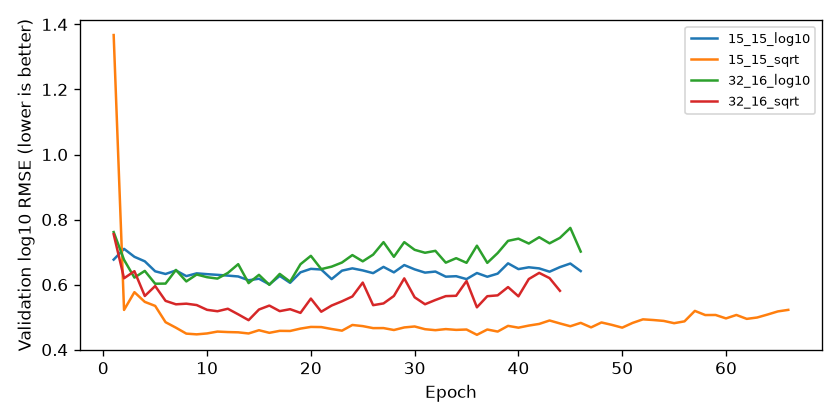

In [28]:
# 8: compare the same validation metric, not differently scaled training losses
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 3.5))
for name, curve in pretraining_history.groupby('candidate', sort=False):
    ax.plot(curve['epoch'], curve['validation_log10_RMSE'].replace(np.inf, np.nan), label=name)
ax.set(xlabel='Epoch', ylabel='Validation log10 RMSE (lower is better)')
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(RUN / 'validation_learning_curves.png', dpi=150)
plt.show()


15–15 with square-root SPM gave the lowest GLORIA validation log error (0.446, epoch 36), but its RMSE was 82.5 mg/L. The 32–16 log-target model did better in mg/L, so we took both configurations to the local comparison.


## 9. S2-SPM local fine-tuning

Use 63 local pairs on 37 dates. Try the GLORIA weights unchanged, update just the output layer, or update all layers at a smaller learning rate. Compare with matching random-start runs, including a faster learning rate, a random forest and a constant (the training geometric mean).

Use GLORIA training scaling throughout this comparison. The date group left out of each fit also picks the stopping epoch, so these are development scores. Use the median stopping epoch for the final development fit. Save to FINE.


In [49]:
# 9: load source checkpoints and reserve development dates for validation
from sklearn.model_selection import GroupKFold
from sklearn.ensemble import RandomForestRegressor
import joblib

checkpoints = {name: torch.load(PROJECT / 'models/S2_SPM/pretrain_01' / (name+'.pt'),
    map_location='cpu', weights_only=True) for name in ['15_15_sqrt', '32_16_log10']}
fixed_local = pd.read_csv(PREP / 'local_assignments.csv')
dev_ids = fixed_local.loc[fixed_local['sensor'].eq('S2') & fixed_local['target'].eq('SPM')
                          & fixed_local['role'].eq('development'), 'row_id']
tuning_dev = matchups.set_index('row_id').loc[dev_ids].sort_index().reset_index()
tuning_features = checkpoints['15_15_sqrt']['features']
raw_features = ['raw__' + index_columns.get(c, 'Rrs_'+c) for c in tuning_features]
tuning_input = tuning_dev[raw_features].to_numpy()
assert len(tuning_dev) == 63 and np.isfinite(tuning_input).all()
reference = checkpoints['15_15_sqrt']
assert checkpoints['32_16_log10']['features'] == tuning_features
assert checkpoints['32_16_log10']['centre'] == reference['centre']
assert checkpoints['32_16_log10']['spread'] == reference['spread']
tuning_x = torch.tensor((tuning_input-reference['centre'])/reference['spread'], dtype=torch.float32)
tuning_y = tuning_dev['target_value'].to_numpy()
tuning_folds = list(GroupKFold(3, shuffle=True, random_state=42).split(
    tuning_dev, groups=tuning_dev['acquisition_date']))
tuning_dev['fold'] = -1
for fold, (fit, hold) in enumerate(tuning_folds):
    tuning_dev.loc[hold, 'fold'] = fold
assert tuning_dev.groupby('acquisition_date')['fold'].nunique().eq(1).all()
save_fixed(tuning_dev[['row_id', 'acquisition_date', 'fold']], 'local_cv_S2_SPM.csv')
tuning_dev.groupby('fold').agg(observations=('row_id', 'size'), dates=('acquisition_date', 'nunique'))


,observations,dates
fold,,
0,26,13
1,16,12
2,21,12


In [50]:
# 9: the source scaler stays fixed, only the permitted network weights change
def tuning_metrics(y, prediction):
    invalid = int((~np.isfinite(prediction) | (prediction <= 0)).sum())
    if invalid:
        return {'MAE_mg_l': np.nan, 'RMSE_mg_l': np.nan, 'R2': np.nan,
                'log10_RMSE': np.inf, 'invalid': invalid}
    error = prediction-y
    return {'MAE_mg_l': np.mean(abs(error)), 'RMSE_mg_l': np.sqrt(np.mean(error**2)),
        'R2': 1-np.sum(error**2)/np.sum((y-y.mean())**2),
        'log10_RMSE': np.sqrt(np.mean((np.log10(prediction)-np.log10(y))**2)), 'invalid': 0}

def adapt_local(checkpoint, initialisation, mode, lr, x, y, x_val=None, y_val=None, epochs=300):
    torch.manual_seed(42)
    h = checkpoint['hidden']
    model = torch.nn.Sequential(torch.nn.Linear(len(tuning_features), h[0]), torch.nn.ReLU(),
        torch.nn.Linear(h[0], h[1]), torch.nn.ReLU(), torch.nn.Linear(h[1], 1))
    if initialisation == 'pretrained':
        model.load_state_dict(checkpoint['state_dict'])
    if mode == 'frozen':
        return model, 0, []
    if mode == 'head':
        for parameter in model[:-1].parameters():
            parameter.requires_grad_(False)
    optimiser = torch.optim.Adam([p for p in model.parameters() if p.requires_grad],
                                  lr=lr, weight_decay=0.0001)
    target = torch.tensor(np.log10(y) if checkpoint['transform']=='log10' else np.sqrt(y),
                          dtype=torch.float32)
    generator = torch.Generator().manual_seed(42)
    best, state, best_epoch, stale, curve = np.inf, None, None, 0, []
    for epoch in range(1, epochs+1):
        model.train()
        for batch in torch.randperm(len(y), generator=generator).split(32):
            optimiser.zero_grad()
            loss = (model(x[batch]).squeeze(1)-target[batch]).square().mean()
            loss.backward()
            optimiser.step()
        if x_val is None:
            continue
        model.eval()
        with torch.no_grad():
            prediction = invert_target(model(x_val).squeeze(1).numpy().astype(float), checkpoint['transform'])
        scores = tuning_metrics(y_val, prediction)
        curve.append([epoch, scores['log10_RMSE'], scores['invalid']])
        if scores['log10_RMSE'] < best:
            best, state, best_epoch, stale = scores['log10_RMSE'], copy.deepcopy(model.state_dict()), epoch, 0
        else:
            stale += 1
        if state is not None and stale >= 30:
            break
    if state is not None:
        model.load_state_dict(state)
    return model, epochs if x_val is None else best_epoch, curve


In [51]:
# 9: define the bounded comparison before fitting
FINE = PROJECT / 'models/S2_SPM/finetune_01'
assert not FINE.exists(), 'Use a new FINE folder to preserve earlier comparisons.'
FINE.mkdir(parents=True)
settings = []
for checkpoint in checkpoints:
    settings.append([checkpoint+'_pretrained_frozen', checkpoint, 'pretrained', 'frozen', 0.0])
    for initialisation in ['pretrained', 'random']:
        for mode, lr in [('head', 0.001), ('full', 0.0001)]:
            settings.append([checkpoint+'_'+initialisation+'_'+mode, checkpoint, initialisation, mode, lr])
    settings.append([checkpoint+'_random_full_fast', checkpoint, 'random', 'full', 0.001])
settings = pd.DataFrame(settings, columns=['candidate', 'checkpoint', 'initialisation', 'mode', 'lr'])
settings.to_csv(FINE / 'settings.csv', index=False)

fold_records, cv_predictions, fine_curves = [], [], []
for setting in settings.itertuples(index=False):
    checkpoint = checkpoints[setting.checkpoint]
    for fold, (fit, hold) in enumerate(tuning_folds):
        model, best_epoch, curve = adapt_local(checkpoint, setting.initialisation,
            setting.mode, setting.lr, tuning_x[fit], tuning_y[fit], tuning_x[hold], tuning_y[hold])
        with torch.no_grad():
            prediction = invert_target(model(tuning_x[hold]).squeeze(1).numpy().astype(float),
                                        checkpoint['transform'])
        fold_records.append({'candidate': setting.candidate, 'fold': fold,
                             'best_epoch': best_epoch, **tuning_metrics(tuning_y[hold], prediction)})
        cv_predictions.append(tuning_dev.loc[hold, ['row_id', 'acquisition_date', 'target_value']].assign(
            candidate=setting.candidate, fold=fold, prediction_mg_l=prediction))
        fine_curves.extend([[setting.candidate, fold, *row] for row in curve])
    print(setting.candidate, 'done', flush=True)

# Fixed baselines use only each fold's training observations.
for fold, (fit, hold) in enumerate(tuning_folds):
    forest = RandomForestRegressor(n_estimators=200, min_samples_leaf=3, random_state=42, n_jobs=1)
    forest.fit(tuning_x[fit].numpy(), np.log10(tuning_y[fit]))
    baseline_predictions = {'random_forest_log10': 10.0**forest.predict(tuning_x[hold].numpy()),
        'constant_log_mean': np.full(len(hold), 10.0**np.log10(tuning_y[fit]).mean())}
    for name, prediction in baseline_predictions.items():
        fold_records.append({'candidate': name, 'fold': fold, 'best_epoch': np.nan,
                             **tuning_metrics(tuning_y[hold], prediction)})
        cv_predictions.append(tuning_dev.loc[hold, ['row_id', 'acquisition_date', 'target_value']].assign(
            candidate=name, fold=fold, prediction_mg_l=prediction))

fold_results = pd.DataFrame(fold_records)
cv_predictions = pd.concat(cv_predictions, ignore_index=True)
fine_curves = pd.DataFrame(fine_curves, columns=[
    'candidate', 'fold', 'epoch', 'validation_log10_RMSE', 'invalid'])
fold_results.to_csv(FINE / 'fold_results.csv', index=False)
cv_predictions.to_csv(FINE / 'cv_predictions.csv', index=False)
fine_curves.to_csv(FINE / 'learning_curves.csv', index=False)


In [52]:
# 9: pooled development predictions, all 63 rows must be present
local_results = []
for name, part in cv_predictions.groupby('candidate', sort=False):
    assert len(part) == 63 and part['row_id'].is_unique
    local_results.append({'candidate': name,
        **tuning_metrics(part['target_value'].to_numpy(), part['prediction_mg_l'].to_numpy())})
local_results = pd.DataFrame(local_results).sort_values('log10_RMSE')
local_results.to_csv(FINE / 'cv_results.csv', index=False)
local_results.set_index('candidate').round(3)


,MAE_mg_l,RMSE_mg_l,R2,log10_RMSE,invalid
candidate,,,,,
32_16_log10_pretrained_full,18.971,35.600,0.082,0.449,0
32_16_log10_pretrained_head,19.198,35.832,0.070,0.456,0
random_forest_log10,19.052,32.760,0.223,0.469,0
32_16_log10_pretrained_frozen,19.536,37.776,-0.034,0.477,0
15_15_sqrt_random_full_fast,20.271,35.814,0.071,0.480,0
15_15_sqrt_pretrained_full,20.322,36.401,0.040,0.493,0
32_16_log10_random_full_fast,24.639,51.544,-0.925,0.515,0
15_15_sqrt_pretrained_frozen,20.241,37.972,-0.045,0.518,0
15_15_sqrt_pretrained_head,20.242,37.918,-0.042,0.519,0


In [53]:
# 9: refit selected neural versions on development only, with no test monitoring
final_choices = {}
for initialisation in ['pretrained', 'random']:
    eligible = local_results.merge(settings, on='candidate')
    eligible = eligible.loc[eligible['initialisation'].eq(initialisation)
                            & np.isfinite(eligible['log10_RMSE'])].sort_values('log10_RMSE')
    assert len(eligible), 'No valid neural configuration, inspect failures before refitting.'
    chosen = eligible.iloc[0]
    best_epochs = fold_results.loc[fold_results['candidate'].eq(chosen['candidate']), 'best_epoch']
    epochs = int(np.median(best_epochs))
    checkpoint = checkpoints[chosen['checkpoint']]
    model, _, _ = adapt_local(checkpoint, initialisation, chosen['mode'], chosen['lr'],
                              tuning_x, tuning_y, epochs=epochs)
    torch.save({'state_dict': model.state_dict(), 'hidden': checkpoint['hidden'],
        'features': checkpoint['features'], 'transform': checkpoint['transform'],
        'centre': checkpoint['centre'], 'spread': checkpoint['spread'],
        'source_candidate': chosen['checkpoint'], 'local_candidate': chosen['candidate'],
        'local_epochs': epochs, 'mode': chosen['mode'], 'lr': float(chosen['lr'])},
        FINE / ('final_'+initialisation+'.pt'))
    final_choices[initialisation] = {'candidate': chosen['candidate'], 'development_epochs': epochs}

forest = RandomForestRegressor(n_estimators=200, min_samples_leaf=3, random_state=42, n_jobs=1)
forest.fit(tuning_x.numpy(), np.log10(tuning_y))
joblib.dump({'model': forest, 'features': tuning_features, 'centre': reference['centre'],
    'spread': reference['spread'], 'transform': 'log10'}, FINE / 'final_random_forest.joblib')
pd.DataFrame(final_choices).T


,candidate,development_epochs
pretrained,32_16_log10_pretrained_full,33
random,15_15_sqrt_random_full_fast,140


The 32–16 log-target pretrained network had the best development log error (0.449). The best random start scored 0.480 and random forest scored 0.469. RF did better in mg/L (32.8 vs 35.6). Refit the selected networks for 33 and 140 epochs respectively on all 63 development pairs.


## 10. S2-SPM reserved test dates

Compare the three saved S2-SPM models on the same 17 pairs from nine dates. Those dates didn't fit or tune these models. We had included them in early correlations, and seeing these results also limits how blind later evaluation is.


In [54]:
# 10: load the selected models, no fitting or new scaling
EVAL = PROJECT / 'models/S2_SPM/test_01'
assert not EVAL.exists(), 'Saved test results already exist. Read them instead of overwriting.'
FINE = PROJECT / 'models/S2_SPM/finetune_01'
saved_networks = {name: torch.load(FINE / filename, map_location='cpu', weights_only=True)
    for name, filename in [('Pretrained MLP', 'final_pretrained.pt'), ('Random-start MLP', 'final_random.pt')]}
saved_forest = joblib.load(FINE / 'final_random_forest.joblib')
roles = pd.read_csv(DATA / 'model_preparation/local_assignments.csv')
test_ids = roles.loc[roles['sensor'].eq('S2') & roles['target'].eq('SPM') & roles['role'].eq('test'), 'row_id']
test_rows = matchups.set_index('row_id').loc[test_ids].sort_index().reset_index()
assert len(test_rows) == 17 and test_rows['acquisition_date'].nunique() == 9
saved_scaler = saved_networks['Pretrained MLP']
for saved in [saved_networks['Random-start MLP'], saved_forest]:
    for key in ['features', 'centre', 'spread']:
        assert saved[key] == saved_scaler[key]
columns = ['raw__' + index_columns.get(c, 'Rrs_'+c) for c in saved_scaler['features']]
x_test = torch.tensor((test_rows[columns].to_numpy()-saved_scaler['centre'])/saved_scaler['spread'], dtype=torch.float32)
assert torch.isfinite(x_test).all()
test_predictions = test_rows[['row_id', 'sample_id', 'station_id', 'acquisition_date',
                              'datetime_utc', 'acquisition_start_utc', 'target_value', 'target_unit']].copy()
for name, saved in saved_networks.items():
    h = saved['hidden']
    network = torch.nn.Sequential(torch.nn.Linear(len(columns), h[0]), torch.nn.ReLU(),
        torch.nn.Linear(h[0], h[1]), torch.nn.ReLU(), torch.nn.Linear(h[1], 1))
    network.load_state_dict(saved['state_dict'])
    network.eval()
    with torch.no_grad():
        z = network(x_test).squeeze(1).numpy().astype(float)
    test_predictions[name] = invert_target(z, saved['transform'])
test_predictions['Random forest'] = 10.0**saved_forest['model'].predict(x_test.numpy())
EVAL.mkdir(parents=True)
test_predictions.to_csv(EVAL / 'test_predictions.csv', index=False)


In [55]:
# 10: same metrics and every reserved observation for all three models
model_names = ['Pretrained MLP', 'Random-start MLP', 'Random forest']
test_results = pd.DataFrame([{'model': name, 'n': len(test_rows),
    'dates': test_rows['acquisition_date'].nunique(),
    **tuning_metrics(test_rows['target_value'].to_numpy(), test_predictions[name].to_numpy())}
    for name in model_names])
test_results.to_csv(EVAL / 'test_results.csv', index=False)
test_results.set_index('model').round(3)


,n,dates,MAE_mg_l,RMSE_mg_l,R2,log10_RMSE,invalid
model,,,,,,,
Pretrained MLP,17,9,19.440,37.078,0.024,0.408,0
Random-start MLP,17,9,17.792,33.551,0.201,0.364,0
Random forest,17,9,19.630,33.581,0.200,0.385,0


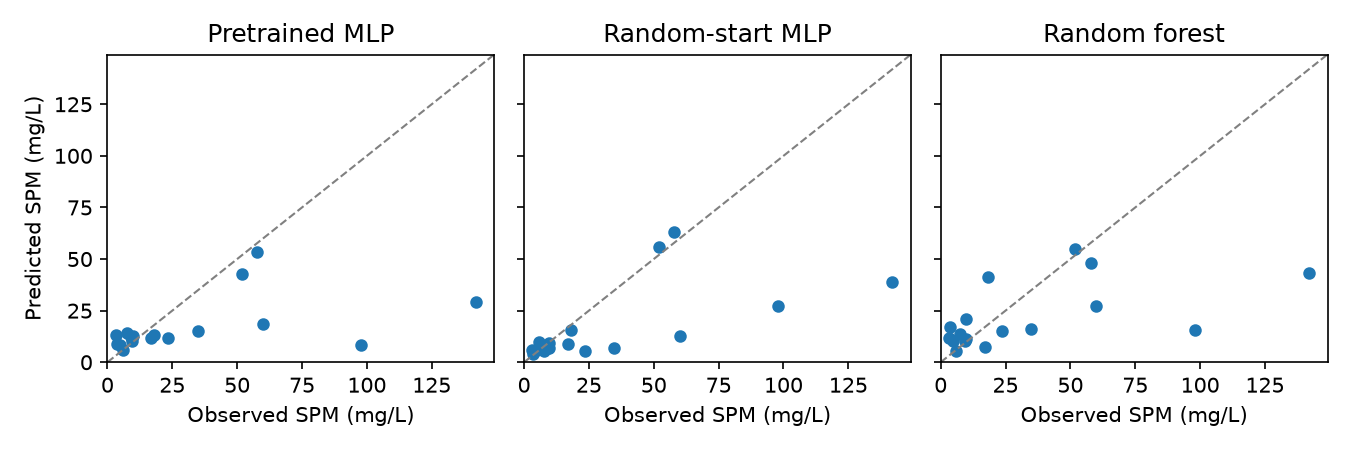

In [56]:
# 10: observed versus predicted SPM, same axes for each model
fig, axes = plt.subplots(1, 3, figsize=(9, 3), sharex=True, sharey=True)
upper = max(test_predictions[['target_value']+model_names].max())*1.05
for ax, name in zip(axes, model_names):
    ax.scatter(test_predictions['target_value'], test_predictions[name], s=25)
    ax.plot([0, upper], [0, upper], color='grey', linestyle='--', linewidth=1)
    ax.set(title=name, xlabel='Observed SPM (mg/L)', xlim=(0, upper), ylim=(0, upper))
axes[0].set_ylabel('Predicted SPM (mg/L)')
fig.tight_layout()
fig.savefig(EVAL / 'observed_predicted.png', dpi=150)
plt.show()


Random start scored 33.6 mg/L RMSE, compared with 37.1 after pretraining. Its log error was lower too (0.364 vs 0.408). All three models missed the highest measurements. With nine dates and different selected network settings, this gives no clear reason to keep the pretraining approach we tested.


## 11. GLORIA satellite-matchup feasibility

Try adding GLORIA field samples matched to actual satellite images. This would add training pairs with the same kind of input as the local data. It is separate from training on measured spectra.

Search for positive labels with coordinates, a declared UTC time and an image within three hours. The catalogue counts possible coverage before cloud and pixel checks. [Search record](data/gloria_catalogue/run.json).


In [57]:
# 11: saved availability, not new training observations
catalogue_counts = pd.read_csv(DATA / 'gloria_catalogue/summary.csv', dtype={'collection': str})
catalogue_counts.loc[catalogue_counts['collection'].ne('004'), [
    'sensor', 'collection', 'target', 'candidate_observations',
    'observations_with_3h_candidate', 'field_dates', 'reported_sites']]


,sensor,collection,target,candidate_observations,observations_with_3h_candidate,field_dates,reported_sites
0,S2,L1C,SPM,294,97,17,6
1,S2,L1C,Secchi,47,22,4,3
2,S3,003,SPM,273,147,32,7
3,S3,003,Secchi,47,25,5,3


Set aside Hawke Bay records with repeated 00:00 UTC times because we couldn't verify that they were sampled at midnight. That leaves 48 S2 and 82 S3 SPM candidates before pixel checks. Secchi adds few dates. [Sample outcomes](gloria_satellite/sample_status.csv).


In [58]:
# 11: actual matchups, with unresolved timestamps kept separate
satellite_gloria = pd.read_csv(PROJECT / 'gloria_satellite/matchups.csv')
gloria_ready = satellite_gloria.loc[~satellite_gloria['time_precision_review']].copy()
cohorts = pd.MultiIndex.from_product([['S2', 'S3'], ['SPM', 'Secchi']], names=['sensor', 'target'])
gloria_ready.groupby(['sensor', 'target']).agg(
    observations=('sample_id', 'nunique'), dates=('acquisition_date', 'nunique'),
    areas=('station_id', 'nunique')
).reindex(cohorts, fill_value=0)


observations  dates  areas
sensor target                            
S2     SPM               19      5      3
       Secchi             5      1      1
S3     SPM               10      4      2
       Secchi             0      0      0

After processing 67 products, usable pairs were still scarce. Five S2 Secchi samples came from one date. No S3 Secchi window passed the main checks. We kept the local time and window rules. Relaxing S3 to five valid pixels would add a few pairs, but we didn't use that rule. Section 16 also excludes GLORIA validation/test areas from training. [Processing checks](gloria_satellite/completion_checks.json).


## 12. ERA5 wind

Wind can stir up and move sediment ([Baeye et al.](https://doi.org/10.1007/s10236-010-0370-7)). Use hourly 10 m [ERA5](https://doi.org/10.24381/cds.adbb2d47) wind from [Open-Meteo](https://open-meteo.com/en/docs/historical-weather-api), nearest 0.25° cell. These are regional estimates.

Use the latest hour at or before the overpass and the previous 6, 12 and 24 hourly values ending there. Average eastward and northward velocities instead of angles, so winds near 0° and 360° are handled correctly. No later hours or filled gaps. [Requests and provenance](weather/run.json).


In [61]:
# 12: saved hourly data and matchup identifiers, no new download
weather_samples = pd.read_csv(PROJECT / 'weather/samples.csv')
wind_hourly = pd.read_csv(PROJECT / 'weather/hourly_wind.csv')
wind_hourly['time_utc'] = pd.to_datetime(wind_hourly['time_utc'], utc=True)
weather_samples['wind_hour_utc'] = pd.to_datetime(weather_samples['wind_hour_utc'], utc=True)
angle = np.deg2rad(wind_hourly['wind_from_deg'])
wind_hourly['wind_u_ms'] = -wind_hourly['wind_speed_ms'] * np.sin(angle)
wind_hourly['wind_v_ms'] = -wind_hourly['wind_speed_ms'] * np.cos(angle)
wind_hourly = wind_hourly.set_index(['cell_id', 'time_utc']).sort_index()


In [62]:
# 12: reconstruct wind features from the saved hours
wind_records = []
eligible_weather = weather_samples.loc[~weather_samples['time_precision_review']]
for row in eligible_weather.drop_duplicates('weather_id').itertuples():
    times = pd.date_range(row.wind_hour_utc - pd.Timedelta(hours=23), row.wind_hour_utc, freq='h')
    history = wind_hourly.loc[row.cell_id].reindex(times)
    assert history[['wind_speed_ms', 'wind_u_ms', 'wind_v_ms']].notna().all().all()
    record = {'weather_id': row.weather_id}
    for n in [1, 6, 12, 24]:
        for name in ['speed', 'u', 'v']:
            record[f'wind_{name}_{n}h_ms'] = history[f'wind_{name}_ms'].tail(n).mean()
        u, v = record[f'wind_u_{n}h_ms'], record[f'wind_v_{n}h_ms']
        record[f'wind_from_{n}h_deg'] = (np.degrees(np.arctan2(-u, -v)) % 360
            if np.hypot(u, v) > 1e-6 else np.nan)
    wind_records.append(record)
wind_features = pd.DataFrame(wind_records)
saved_wind = pd.read_csv(PROJECT / 'weather/wind_features.csv')[wind_features.columns]
pd.testing.assert_frame_equal(wind_features, saved_wind, check_exact=False, rtol=1e-10, atol=1e-10)


In [63]:
# 12: primary collections only, with uncertain times shown separately
weather_matchups = pd.read_csv(PROJECT / 'weather/matchups_wind.csv', dtype={'collection': str})
weather_matchups.loc[weather_matchups['primary_collection']].groupby(
    ['dataset_origin', 'sensor', 'target', 'weather_status']).agg(
    observations=('row_id', 'size'), dates=('acquisition_date', 'nunique'))


observations  dates
dataset_origin sensor target weather_status                       
GLORIA         S2     SPM    complete                    19      5
                             timestamp_review            29      3
                      Secchi complete                     5      1
               S3     SPM    complete                    10      4
                             timestamp_review            14      1
local          S2     SPM    complete                    80     46
                      Secchi complete                    52     28
               S3     SPM    complete                   134     78
                      Secchi complete                    79     39

## 13. Local-only baselines

Compare four local models on the same complete rows and date groups: 63 S2-SPM, 44 S2-Secchi, 104 S3-SPM and 59 S3-Secchi. No wind or GLORIA additions.

- Constant: predict the geometric mean of the training measurements.
- Red-edge power law: fit a line between log₁₀(reflectance) and log₁₀(target).
- Random forest: 200 trees, at least three samples per leaf, eight optical inputs, no scaling.
- Support vector regression: same inputs, training-only scaling and a nonlinear radial basis kernel. Choose C and epsilon inside the training dates.

Fit log₁₀(target) and convert back without bias correction. Rotate the held-out date group three times. [Random forest](https://doi.org/10.1023/A:1010933404324) · [SVR](https://doi.org/10.1023/B:STCO.0000035301.49549.88) · [Nested validation](https://scikit-learn.org/1.7/auto_examples/model_selection/plot_nested_cross_validation_iris.html).


In [64]:
# 13: development data only, existing features and S2-SPM folds
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import RobustScaler, FunctionTransformer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.dummy import DummyRegressor

BASE = PROJECT / 'models/local_baselines_01'
assert not BASE.exists(), 'Read the saved run or use a new folder.'
BASE.mkdir(parents=True)
baseline_roles = pd.read_csv(PREP / 'local_assignments.csv')
baseline_ids = baseline_roles.loc[baseline_roles['role'].eq('development'), 'row_id']
baseline_dev = matchups.set_index('row_id').loc[baseline_ids].sort_index().reset_index()
baseline_cohorts, fold_records, baseline_counts = {}, [], []
for (sensor, target), group in baseline_dev.groupby(['sensor', 'target']):
    group = group.reset_index(drop=True)
    columns = ['raw__' + index_columns.get(f, 'Rrs_'+f) for f in selected_inputs[sensor, target]]
    if (sensor, target) == ('S2', 'SPM'):
        saved = pd.read_csv(PREP / 'local_cv_S2_SPM.csv').set_index('row_id')
        group['fold'] = saved.loc[group['row_id'], 'fold'].to_numpy()
    else:
        group['fold'] = -1
        for fold, (_, hold) in enumerate(GroupKFold(3, shuffle=True, random_state=42).split(
                group, groups=group['acquisition_date'])):
            group.loc[hold, 'fold'] = fold
    group['input_complete'] = np.isfinite(group[columns]).all(axis=1)
    fold_records.append(group[['row_id', 'sensor', 'target', 'acquisition_date', 'fold', 'input_complete']])
    complete = group.loc[group['input_complete']].reset_index(drop=True)
    baseline_counts.append([sensor, target, len(group), len(complete),
                            complete['acquisition_date'].nunique(), len(group)-len(complete)])
    baseline_cohorts[sensor, target] = (complete, columns)
baseline_folds = pd.concat(fold_records, ignore_index=True)
baseline_folds.to_csv(BASE / 'fold_assignments.csv', index=False)
baseline_counts = pd.DataFrame(baseline_counts, columns=[
    'sensor', 'target', 'development_rows', 'complete_rows', 'dates', 'incomplete'])
baseline_counts.to_csv(BASE / 'counts.csv', index=False)
baseline_counts


,sensor,target,development_rows,complete_rows,dates,incomplete
0,S2,SPM,63,63,37,0
1,S2,Secchi,44,44,24,0
2,S3,SPM,107,104,61,3
3,S3,Secchi,61,59,27,2


In [65]:
# 13: held-out development predictions, SVR tuning stays inside each training set
baseline_predictions, svr_choices, power_coefficients = [], [], []
for (sensor, target), (group, columns) in baseline_cohorts.items():
    edge = 'raw__Rrs_' + ('B5' if sensor == 'S2' else 'Oa11')
    for fold in range(3):
        train, hold = group.loc[group['fold'].ne(fold)], group.loc[group['fold'].eq(fold)]
        assert set(train['acquisition_date']).isdisjoint(hold['acquisition_date'])
        log_y = np.log10(train['target_value'].to_numpy())
        models = {
            'Constant': DummyRegressor(strategy='mean'),
            'Power law': make_pipeline(FunctionTransformer(np.log10), LinearRegression()),
            'Random forest': RandomForestRegressor(n_estimators=200, min_samples_leaf=3,
                                                   random_state=42, n_jobs=1),
            'SVR': GridSearchCV(make_pipeline(RobustScaler(), SVR(kernel='rbf', gamma='scale')),
                {'svr__C': [1, 10, 100], 'svr__epsilon': [0.05, 0.1]},
                cv=GroupKFold(3, shuffle=True, random_state=42),
                scoring='neg_mean_squared_error', n_jobs=1, error_score='raise')}
        for name, model in models.items():
            inputs = [edge] if name == 'Power law' else columns
            if name == 'Power law':
                assert train[edge].gt(0).all() and hold[edge].gt(0).all()
            fit_options = {'groups': train['acquisition_date']} if name == 'SVR' else {}
            model.fit(train[inputs].to_numpy(), log_y, **fit_options)
            prediction = 10.0**model.predict(hold[inputs].to_numpy())
            assert np.isfinite(prediction).all() and (prediction > 0).all()
            baseline_predictions.append(hold[['row_id', 'sensor', 'target', 'target_unit',
                'acquisition_date', 'fold', 'target_value']].assign(model=name, prediction=prediction))
            if name == 'SVR':
                svr_choices.append({'sensor': sensor, 'target': target, 'fold': fold, **model.best_params_})
            if name == 'Power law':
                linear = model.named_steps['linearregression']
                power_coefficients.append({'sensor': sensor, 'target': target, 'fold': fold,
                    'a': 10.0**linear.intercept_, 'b': linear.coef_[0], 'input': edge})
    print(sensor, target, 'done')
baseline_predictions = pd.concat(baseline_predictions, ignore_index=True)
baseline_predictions.to_csv(BASE / 'development_predictions.csv', index=False)
pd.DataFrame(svr_choices).to_csv(BASE / 'svr_choices.csv', index=False)
pd.DataFrame(power_coefficients).to_csv(BASE / 'power_coefficients.csv', index=False)


S2 SPM done
S2 Secchi done
S3 SPM done
S3 Secchi done


In [66]:
# 13: pooled held-out development errors, units differ between targets
baseline_results = []
for (sensor, target, unit, model), group in baseline_predictions.groupby(
        ['sensor', 'target', 'target_unit', 'model'], sort=False):
    observed, predicted = group['target_value'].to_numpy(), group['prediction'].to_numpy()
    error = predicted-observed
    baseline_results.append({'sensor': sensor, 'target': target, 'unit': unit, 'model': model,
        'n': len(group), 'dates': group['acquisition_date'].nunique(),
        'MAE': np.mean(abs(error)), 'RMSE': np.sqrt(np.mean(error**2)),
        'R2': 1-np.sum(error**2)/np.sum((observed-observed.mean())**2),
        'log10_RMSE': np.sqrt(np.mean((np.log10(predicted)-np.log10(observed))**2))})
baseline_results = pd.DataFrame(baseline_results)
baseline_results.to_csv(BASE / 'development_results.csv', index=False)
baseline_results.set_index(['sensor', 'target', 'unit', 'model']).round(3)


n  dates     MAE    RMSE     R2  log10_RMSE
sensor target unit model                                                       
S2     SPM    mg/L Constant        63     37  23.734  40.667 -0.198       0.588
                   Power law       63     37  18.070  33.478  0.188       0.440
                   Random forest   63     37  19.052  32.760  0.223       0.469
                   SVR             63     37  19.637  33.538  0.185       0.472
       Secchi m    Constant        44     24   1.302   1.962 -0.142       0.419
                   Power law       44     24   0.828   1.368  0.445       0.208
                   Random forest   44     24   0.768   1.329  0.476       0.198
                   SVR             44     24   0.845   1.504  0.329       0.230
S3     SPM    mg/L Constant       104     61  16.034  28.217 -0.184       0.626
                   Power law      104     61  10.602  20.384  0.382       0.463
                   Random forest  104     61   9.572  17.530  0.543       0.384
                   SVR            104     61  10.823  20.146  0.396       0.412
       Secchi m    Constant        59     27   1.800   2.344 -0.295       0.468
                   Power law       59     27   1.697   5.394 -5.856       0.291
                   Random forest   59     27   0.939   1.325  0.586       0.224
                   SVR             59     27   1.094   1.405  0.535       0.313

For S2-SPM, the power law had lower proportional error, but random forest had lower RMSE in mg/L (32.8 vs 33.5). The S3 Secchi power law predicted 42.3 m for a measured 2.6 m. We kept that miss in the scores. These are development results. The neural comparison used the same date groups but also used the checked groups to pick stopping epochs. [Run details](models/local_baselines_01/run.json).


## 14. Does wind help?

Compare optics only, wind only and both. Wind adds six inputs: latest speed, average speed over 6/12/24 hours, and 24-hour mean eastward and northward velocity. Keep the samples, dates and random forest settings fixed. Retune SVR inside the training dates.


In [67]:
# 14: join wind by the exact matchup ID and reuse saved development folds
WIND_RUN = PROJECT / 'models/wind_comparison_01'
assert not WIND_RUN.exists(), 'Read the saved run or use a new folder.'
WIND_RUN.mkdir(parents=True)
wind_inputs = ['wind_speed_1h_ms', 'wind_speed_6h_ms', 'wind_speed_12h_ms',
               'wind_speed_24h_ms', 'wind_u_24h_ms', 'wind_v_24h_ms']
wind_folds = pd.read_csv(PROJECT / 'models/local_baselines_01/fold_assignments.csv')
wind_ids = wind_folds.loc[wind_folds['input_complete'], 'row_id']
wind_dev = matchups.set_index('row_id').loc[wind_ids].reset_index()
wind_dev = wind_dev.merge(wind_folds[['row_id', 'fold']], on='row_id', validate='one_to_one')
wind_table = pd.read_csv(PROJECT / 'weather/matchups_wind.csv')
wind_table = wind_table.loc[wind_table['dataset_origin'].eq('local') & wind_table['weather_status'].eq('complete')]
wind_dev = wind_dev.merge(wind_table[['row_id', 'cell_id', 'wind_hour_utc']+wind_inputs],
                         on='row_id', how='left', validate='one_to_one')
assert len(wind_dev) == len(wind_ids) and np.isfinite(wind_dev[wind_inputs]).all().all()
wind_dev['wind_hour_utc'] = pd.to_datetime(wind_dev['wind_hour_utc'], utc=True)
wind_dev[['row_id', 'sensor', 'target', 'acquisition_date', 'fold', 'cell_id',
          'wind_hour_utc']+wind_inputs].to_csv(WIND_RUN / 'development_inputs.csv', index=False)
wind_dev.groupby(['sensor', 'target']).agg(
    observations=('row_id', 'size'), dates=('acquisition_date', 'nunique'))


observations  dates
sensor target                     
S2     SPM               63     37
       Secchi            44     24
S3     SPM              104     61
       Secchi            59     27

In [68]:
# 14: same rows and folds, change only the input set
previous = pd.read_csv(PROJECT / 'models/local_baselines_01/development_predictions.csv')
wind_predictions = [previous.loc[previous['model'].isin(['Random forest', 'SVR'])].assign(inputs='Reflectance')]
wind_choices, wind_inner_scores = [], []
for (sensor, target), group in wind_dev.groupby(['sensor', 'target']):
    spectral = ['raw__' + index_columns.get(f, 'Rrs_'+f) for f in selected_inputs[sensor, target]]
    for inputs, columns in [('Wind', wind_inputs), ('Reflectance + wind', spectral+wind_inputs)]:
        for fold in range(3):
            train, hold = group.loc[group['fold'].ne(fold)], group.loc[group['fold'].eq(fold)]
            assert set(train['acquisition_date']).isdisjoint(hold['acquisition_date'])
            models = {
                'Random forest': RandomForestRegressor(n_estimators=200, min_samples_leaf=3,
                                                       random_state=42, n_jobs=1),
                'SVR': GridSearchCV(make_pipeline(RobustScaler(), SVR(kernel='rbf', gamma='scale')),
                    {'svr__C': [1, 10, 100], 'svr__epsilon': [0.05, 0.1]},
                    cv=GroupKFold(3, shuffle=True, random_state=42),
                    scoring='neg_mean_squared_error', n_jobs=1, error_score='raise')}
            for name, model in models.items():
                options = {'groups': train['acquisition_date']} if name == 'SVR' else {}
                model.fit(train[columns].to_numpy(), np.log10(train['target_value']), **options)
                prediction = 10.0**model.predict(hold[columns].to_numpy())
                assert np.isfinite(prediction).all() and (prediction > 0).all()
                wind_predictions.append(hold[['row_id', 'sensor', 'target', 'target_unit',
                    'acquisition_date', 'fold', 'target_value']].assign(
                    model=name, inputs=inputs, prediction=prediction))
                if name == 'SVR':
                    wind_choices.append({'sensor': sensor, 'target': target, 'inputs': inputs,
                                         'fold': fold, **model.best_params_})
                    scores = pd.DataFrame(model.cv_results_)
                    wind_inner_scores.append(scores[['param_svr__C', 'param_svr__epsilon',
                        'mean_test_score', 'rank_test_score']].assign(
                        sensor=sensor, target=target, inputs=inputs, fold=fold))
    print(sensor, target, 'done')
wind_predictions = pd.concat(wind_predictions, ignore_index=True)
wind_predictions.to_csv(WIND_RUN / 'development_predictions.csv', index=False)
pd.DataFrame(wind_choices).to_csv(WIND_RUN / 'svr_choices.csv', index=False)
pd.concat(wind_inner_scores, ignore_index=True).to_csv(WIND_RUN / 'inner_scores.csv', index=False)


S2 SPM done
S2 Secchi done
S3 SPM done
S3 Secchi done


In [69]:
# 14: paired development errors, the same observations in every input set
wind_results = []
for (sensor, target, unit, model, inputs), group in wind_predictions.groupby(
        ['sensor', 'target', 'target_unit', 'model', 'inputs'], sort=False):
    observed, predicted = group['target_value'].to_numpy(), group['prediction'].to_numpy()
    error = predicted-observed
    wind_results.append({'sensor': sensor, 'target': target, 'unit': unit,
        'model': model, 'inputs': inputs, 'n': len(group), 'dates': group['acquisition_date'].nunique(),
        'MAE': np.mean(abs(error)), 'RMSE': np.sqrt(np.mean(error**2)),
        'R2': 1-np.sum(error**2)/np.sum((observed-observed.mean())**2),
        'log10_RMSE': np.sqrt(np.mean((np.log10(predicted)-np.log10(observed))**2))})
wind_results = pd.DataFrame(wind_results)
wind_results.to_csv(WIND_RUN / 'development_results.csv', index=False)
wind_summary = wind_results.pivot(index=['sensor', 'target', 'unit', 'model'],
    columns='inputs', values=['log10_RMSE', 'RMSE', 'R2'])
wind_summary = wind_summary.reindex(columns=pd.MultiIndex.from_product(
    [['log10_RMSE', 'RMSE', 'R2'], ['Reflectance', 'Wind', 'Reflectance + wind']]))
wind_summary.round(3)


log10_RMSE                                  RMSE                                     R2                          
                                 Reflectance   Wind Reflectance + wind Reflectance    Wind Reflectance + wind Reflectance   Wind Reflectance + wind
sensor target unit model                                                                                                                           
S2     SPM    mg/L Random forest       0.469  0.640              0.466      32.760  42.290             33.139       0.223 -0.296              0.204
                   SVR                 0.472  0.757              0.517      33.538  50.759             36.620       0.185 -0.867              0.028
       Secchi m    Random forest       0.198  0.452              0.190       1.329   2.017              1.314       0.476 -0.207              0.488
                   SVR                 0.230  0.428              0.260       1.504   1.990              1.896       0.329 -0.175             -0.067
S3     SPM    mg/L Random forest       0.384  0.611              0.368      17.530  26.479             17.544       0.543 -0.043              0.542
                   SVR                 0.412  0.653              0.434      20.146  26.476             21.532       0.396 -0.043              0.310
       Secchi m    Random forest       0.224  0.526              0.221       1.325   2.538              1.335       0.586 -0.518              0.580
                   SVR                 0.313  0.703              0.330       1.405   2.901              1.647       0.535 -0.984              0.361

Wind barely changed random forest RMSE and made SVR worse in all four comparisons. Wind-only R² was negative. We kept optical inputs. This only tests these wind summaries, not whether wind affects sediment. [Run details](models/wind_comparison_01/run.json).


## 15. S3 centre pixel

Does one 300 m S3 pixel match a field sample better than the 900 m window? Keep the same images and nine-pixel quality check, but use the centre value and rebuild the indices. Compare on rows complete for both footprints. Rerunning the extraction needs the cutouts and their receipts.


In [70]:
# 15: read the recorded native centre and keep the original selection
import json
from netCDF4 import Dataset
from olci_native import decoded, as_uint, flag_definitions, mask_flags

CENTRE = PROJECT / 'models/s3_centre_01'
assert not CENTRE.exists(), 'Read the saved run or use a new folder.'
CENTRE.mkdir(parents=True)
centre_folds = pd.read_csv(PROJECT / 'models/local_baselines_01/fold_assignments.csv')
centre_folds = centre_folds.loc[centre_folds['sensor'].eq('S3') & centre_folds['input_complete']]
centre_dev = matchups.set_index('row_id').loc[centre_folds['row_id']].reset_index()
centre_dev = centre_dev.merge(centre_folds[['row_id', 'fold']], on='row_id', validate='one_to_one')
centre_records = []
for row in centre_dev.itertuples():
    receipt = json.loads(Path(row.source_receipt).read_text())
    with Dataset(row.cutout_absolute) as nc:
        assert nc.source_product_id == row.product_id == receipt['product_id']
        i, j = int(nc.central_row_in_cutout), int(nc.central_column_in_cutout)
        selection = (slice(i-1, i+2), slice(j-1, j+2))
        flags = nc['WQSF']
        good, _ = mask_flags(as_uint(flags, selection), flag_definitions(flags), '003')
        assert good.shape == (3, 3) and good.all()
        record = {'row_id': row.row_id, 'centre_row': i, 'centre_column': j}
        for band in ['Oa06', 'Oa08', 'Oa11']:
            factor = receipt['metadata'][band]['rrs_factor']
            assert np.isclose(factor, 1/np.pi)
            record['centre__Rrs_'+band] = float(decoded(nc[band+'_reflectance'], (i, j)))*factor
        centre_records.append(record)
centre_values = pd.DataFrame(centre_records)
g, r, e = [centre_values['centre__Rrs_'+b] for b in ['Oa06', 'Oa08', 'Oa11']]
for name, a, b, nd in [('NDTI', r, g, True), ('red_green_ratio', r, g, False),
        ('rededge_red_ratio', e, r, False), ('rededge_green_ratio', e, g, False),
        ('ND_rededge_red', e, r, True)]:
    centre_values['centre__'+name] = ((a-b)/(a+b) if nd else a/b).where((a>1e-6) & (b>1e-6))
centre_columns = [c for c in centre_values if c.startswith('centre__')]
centre_values['centre_complete'] = np.isfinite(centre_values[centre_columns]).all(axis=1)
centre_values.to_csv(CENTRE / 'centre_features.csv', index=False)
centre_dev = centre_dev.merge(centre_values, on='row_id', validate='one_to_one')
centre_counts = centre_dev.groupby('target').agg(
    window_complete=('row_id', 'size'), paired_complete=('centre_complete', 'sum'))
centre_counts['centre_incomplete'] = centre_counts['window_complete']-centre_counts['paired_complete']
centre_counts.to_csv(CENTRE / 'counts.csv')
centre_paired = centre_dev.loc[centre_dev['centre_complete']].copy()
centre_weather = pd.read_csv(PROJECT / 'weather/matchups_wind.csv')
centre_paired = centre_paired.merge(centre_weather[['row_id']+wind_inputs], on='row_id',
                                  how='left', validate='one_to_one')
assert np.isfinite(centre_paired[wind_inputs]).all().all()
centre_paired[['row_id', 'target', 'acquisition_date', 'fold']].to_csv(CENTRE / 'paired_rows.csv', index=False)
centre_counts


,window_complete,paired_complete,centre_incomplete
target,,,
SPM,104,103,1
Secchi,59,58,1


In [71]:
# 15: refit both footprints on identical rows, with the same optional wind inputs
centre_predictions, centre_choices = [], []
for target, group in centre_paired.groupby('target'):
    suffixes = [index_columns.get(f, 'Rrs_'+f) for f in selected_inputs['S3', target]]
    for footprint, prefix in [('3x3 mean', 'raw__'), ('Centre', 'centre__')]:
        for wind in ['No', 'Yes']:
            columns = [prefix+c for c in suffixes] + (wind_inputs if wind == 'Yes' else [])
            for fold in range(3):
                train, hold = group.loc[group['fold'].ne(fold)], group.loc[group['fold'].eq(fold)]
                assert set(train['acquisition_date']).isdisjoint(hold['acquisition_date'])
                models = {
                    'Random forest': RandomForestRegressor(n_estimators=200, min_samples_leaf=3,
                                                           random_state=42, n_jobs=1),
                    'SVR': GridSearchCV(make_pipeline(RobustScaler(), SVR(kernel='rbf', gamma='scale')),
                        {'svr__C': [1, 10, 100], 'svr__epsilon': [0.05, 0.1]},
                        cv=GroupKFold(3, shuffle=True, random_state=42),
                        scoring='neg_mean_squared_error', n_jobs=1, error_score='raise')}
                for name, model in models.items():
                    options = {'groups': train['acquisition_date']} if name == 'SVR' else {}
                    model.fit(train[columns].to_numpy(), np.log10(train['target_value']), **options)
                    prediction = 10.0**model.predict(hold[columns].to_numpy())
                    assert np.isfinite(prediction).all() and (prediction > 0).all()
                    centre_predictions.append(hold[['row_id', 'target', 'target_unit',
                        'acquisition_date', 'fold', 'target_value']].assign(
                        footprint=footprint, wind=wind, model=name, prediction=prediction))
                    if name == 'SVR':
                        centre_choices.append({'target': target, 'footprint': footprint,
                            'wind': wind, 'fold': fold, **model.best_params_})
    print(target, 'done')
centre_predictions = pd.concat(centre_predictions, ignore_index=True)
centre_predictions.to_csv(CENTRE / 'development_predictions.csv', index=False)
pd.DataFrame(centre_choices).to_csv(CENTRE / 'svr_choices.csv', index=False)


SPM done
Secchi done


In [72]:
# 15: paired development errors, not directly comparable with the larger earlier cohort
centre_results = []
for (target, unit, model, wind, footprint), group in centre_predictions.groupby(
        ['target', 'target_unit', 'model', 'wind', 'footprint'], sort=False):
    observed, predicted = group['target_value'].to_numpy(), group['prediction'].to_numpy()
    error = predicted-observed
    centre_results.append({'target': target, 'unit': unit, 'model': model,
        'wind': wind, 'footprint': footprint, 'n': len(group),
        'dates': group['acquisition_date'].nunique(),
        'MAE': np.mean(abs(error)), 'RMSE': np.sqrt(np.mean(error**2)),
        'R2': 1-np.sum(error**2)/np.sum((observed-observed.mean())**2),
        'log10_RMSE': np.sqrt(np.mean((np.log10(predicted)-np.log10(observed))**2))})
centre_results = pd.DataFrame(centre_results)
centre_results.to_csv(CENTRE / 'development_results.csv', index=False)
centre_results.pivot(index=['target', 'unit', 'model', 'wind'],
    columns='footprint', values=['log10_RMSE', 'RMSE', 'R2']).round(3)


log10_RMSE            RMSE               R2       
footprint                        3x3 mean Centre 3x3 mean  Centre 3x3 mean Centre
target unit model         wind                                                   
SPM    mg/L Random forest No        0.385  0.395   17.676  17.524    0.538  0.546
                          Yes       0.375  0.376   17.606  17.318    0.541  0.556
            SVR           No        0.412  0.416   20.252  20.818    0.393  0.359
                          Yes       0.431  0.437   21.682  22.377    0.305  0.259
Secchi m    Random forest No        0.215  0.224    1.221   1.296    0.654  0.610
                          Yes       0.216  0.223    1.243   1.308    0.641  0.603
            SVR           No        0.309  0.335    1.305   1.513    0.605  0.469
                          Yes       0.308  0.320    1.422   1.545    0.531  0.446

The centre pixel did not improve proportional error, with or without wind. Both footprints were scored on the same 103 SPM and 58 Secchi pairs. We kept the 3 × 3 means. [Run details](models/s3_centre_01/run.json).


## 16. Add GLORIA satellite matchups

Add the actual GLORIA satellite–field pairs to training, then score the same local observations as before. Keep the eight optical inputs and S3 window means. No wind.

Use only GLORIA training areas with complete inputs, accepted quality and verified times. We added 19 S2-SPM pairs on five dates, five S2-Secchi pairs on one date and ten S3-SPM pairs on four dates. None qualified for S3-Secchi. The local dates left out for scoring stay unchanged.


In [73]:
# 16: distinguish prepared GLORIA data from training-eligible additions
EXPAND = PROJECT / 'models/gloria_expansion_01'
assert not EXPAND.exists(), 'Read the saved run or use a new folder.'
EXPAND.mkdir(parents=True)
gloria_sat = pd.read_csv(PROJECT / 'gloria_satellite/matchups.csv', dtype={'collection': str})
expansion_source_roles = pd.read_csv(PREP / 'gloria_assignments.csv')
gloria_sat = gloria_sat.merge(expansion_source_roles[['GLORIA_ID', 'geographic_group', 'role']].rename(
    columns={'role': 'gloria_role'}), on='GLORIA_ID', how='left', validate='many_to_one')
gloria_sat['input_complete'] = False
for (sensor, target), group in gloria_sat.groupby(['sensor', 'target']):
    columns = ['raw__' + index_columns.get(f, 'Rrs_'+f) for f in selected_inputs[sensor, target]]
    gloria_sat.loc[group.index, 'input_complete'] = np.isfinite(group[columns]).all(axis=1)
gloria_sat['training_eligible'] = (~gloria_sat['time_precision_review']
    & gloria_sat['gloria_role'].eq('train') & gloria_sat['input_complete']
    & gloria_sat['target_value'].gt(0)
    & (gloria_sat['sensor'].eq('S2') | gloria_sat['collection'].eq('003')))
gloria_sat[['row_id', 'GLORIA_ID', 'sensor', 'target', 'geographic_group', 'gloria_role',
    'time_precision_review', 'input_complete', 'training_eligible']].to_csv(
    EXPAND / 'eligibility.csv', index=False)
gloria_added = gloria_sat.loc[gloria_sat['training_eligible']].copy()
gloria_added['target_unit'] = gloria_added['unit']
expansion_local_roles = pd.read_csv(PREP / 'local_assignments.csv')
assert set(gloria_added['acquisition_date']).isdisjoint(expansion_local_roles['acquisition_date'])
expansion_folds = pd.read_csv(PROJECT / 'models/local_baselines_01/fold_assignments.csv')
expansion_ids = expansion_folds.loc[expansion_folds['input_complete'], 'row_id']
expansion_dev = matchups.set_index('row_id').loc[expansion_ids].reset_index()
expansion_dev = expansion_dev.merge(expansion_folds[['row_id', 'fold']], on='row_id', validate='one_to_one')
expansion_counts = expansion_dev.groupby(['sensor', 'target']).agg(
    local_development=('row_id', 'size'), local_dates=('acquisition_date', 'nunique'))
added_counts = gloria_added.groupby(['sensor', 'target']).agg(
    GLORIA_added=('row_id', 'size'), GLORIA_dates=('acquisition_date', 'nunique'))
expansion_counts = expansion_counts.join(added_counts).fillna(0).astype(int)
expansion_counts.to_csv(EXPAND / 'counts.csv')
gloria_added.to_csv(EXPAND / 'training_additions.csv', index=False)
expansion_counts


local_development  local_dates  GLORIA_added  GLORIA_dates
sensor target                                                            
S2     SPM                    63           37            19             5
       Secchi                 44           24             5             1
S3     SPM                   104           61            10             4
       Secchi                 59           27             0             0

In [74]:
# 16: validate on local dates only, with external rows added to training
old_predictions = pd.read_csv(PROJECT / 'models/local_baselines_01/development_predictions.csv')
expansion_predictions = [old_predictions.assign(training='Local only')]
expansion_choices, expansion_power, expansion_inner_rows = [], [], []
for (sensor, target), group in expansion_dev.groupby(['sensor', 'target']):
    extra = gloria_added.loc[gloria_added['sensor'].eq(sensor) & gloria_added['target'].eq(target)]
    if extra.empty:
        print(sensor, target, 'no eligible GLORIA additions')
        continue
    columns = ['raw__' + index_columns.get(f, 'Rrs_'+f) for f in selected_inputs[sensor, target]]
    edge = 'raw__Rrs_' + ('B5' if sensor == 'S2' else 'Oa11')
    for fold in range(3):
        local_train = group.loc[group['fold'].ne(fold)]
        hold = group.loc[group['fold'].eq(fold)]
        train = pd.concat([local_train, extra], ignore_index=True)
        assert set(train['acquisition_date']).isdisjoint(hold['acquisition_date'])
        auxiliary_indices = np.arange(len(local_train), len(train))
        inner_folds = []
        for inner, (a, b) in enumerate(GroupKFold(3, shuffle=True, random_state=42).split(
                local_train, groups=local_train['acquisition_date'])):
            inner_folds.append((np.r_[a, auxiliary_indices], b))
            expansion_inner_rows.append(local_train.iloc[b][['row_id', 'acquisition_date']].assign(
                sensor=sensor, target=target, outer_fold=fold, inner_validation_fold=inner))
        models = {
            'Constant': DummyRegressor(strategy='mean'),
            'Power law': make_pipeline(FunctionTransformer(np.log10), LinearRegression()),
            'Random forest': RandomForestRegressor(n_estimators=200, min_samples_leaf=3,
                                                   random_state=42, n_jobs=1),
            'SVR': GridSearchCV(make_pipeline(RobustScaler(), SVR(kernel='rbf', gamma='scale')),
                {'svr__C': [1, 10, 100], 'svr__epsilon': [0.05, 0.1]}, cv=inner_folds,
                scoring='neg_mean_squared_error', n_jobs=1, error_score='raise')}
        for name, model in models.items():
            inputs = [edge] if name == 'Power law' else columns
            model.fit(train[inputs].to_numpy(), np.log10(train['target_value']))
            prediction = 10.0**model.predict(hold[inputs].to_numpy())
            assert np.isfinite(prediction).all() and (prediction > 0).all()
            expansion_predictions.append(hold[['row_id', 'sensor', 'target', 'target_unit',
                'acquisition_date', 'fold', 'target_value']].assign(
                model=name, training='Local + GLORIA', prediction=prediction))
            if name == 'SVR':
                expansion_choices.append({'sensor': sensor, 'target': target, 'fold': fold, **model.best_params_})
            if name == 'Power law':
                linear = model.named_steps['linearregression']
                expansion_power.append({'sensor': sensor, 'target': target, 'fold': fold,
                    'a': 10.0**linear.intercept_, 'b': linear.coef_[0]})
    print(sensor, target, 'done')
expansion_predictions = pd.concat(expansion_predictions, ignore_index=True)
expansion_predictions.to_csv(EXPAND / 'development_predictions.csv', index=False)
pd.DataFrame(expansion_choices).to_csv(EXPAND / 'svr_choices.csv', index=False)
pd.DataFrame(expansion_power).to_csv(EXPAND / 'power_coefficients.csv', index=False)
pd.concat(expansion_inner_rows, ignore_index=True).to_csv(EXPAND / 'local_inner_validation.csv', index=False)


S2 SPM done
S2 Secchi done
S3 SPM done
S3 Secchi no eligible GLORIA additions


In [75]:
# 16: paired local validation errors, not scores on the added GLORIA rows
expansion_results = []
for (sensor, target, unit, model, training), group in expansion_predictions.groupby(
        ['sensor', 'target', 'target_unit', 'model', 'training'], sort=False):
    observed, predicted = group['target_value'].to_numpy(), group['prediction'].to_numpy()
    error = predicted-observed
    expansion_results.append({'sensor': sensor, 'target': target, 'unit': unit,
        'model': model, 'training': training, 'n_local_validation': len(group),
        'dates': group['acquisition_date'].nunique(), 'MAE': np.mean(abs(error)),
        'RMSE': np.sqrt(np.mean(error**2)),
        'R2': 1-np.sum(error**2)/np.sum((observed-observed.mean())**2),
        'log10_RMSE': np.sqrt(np.mean((np.log10(predicted)-np.log10(observed))**2))})
expansion_results = pd.DataFrame(expansion_results)
expansion_results.to_csv(EXPAND / 'development_results.csv', index=False)
expansion_results.pivot(index=['sensor', 'target', 'unit', 'model'],
    columns='training', values=['log10_RMSE', 'RMSE', 'R2']).round(3)


log10_RMSE                      RMSE                        R2           
training                         Local + GLORIA Local only Local + GLORIA Local only Local + GLORIA Local only
sensor target unit model                                                                                      
S2     SPM    mg/L Constant               0.583      0.588         40.390     40.667         -0.182     -0.198
                   Power law              0.438      0.440         33.466     33.478          0.189      0.188
                   Random forest          0.470      0.469         34.767     32.760          0.124      0.223
                   SVR                    0.552      0.472         50.283     33.538         -0.832      0.185
       Secchi m    Constant               0.420      0.419          1.977      1.962         -0.159     -0.142
                   Power law              0.207      0.208          1.342      1.368          0.466      0.445
                   Random forest          0.209      0.198          1.329      1.329          0.476      0.476
                   SVR                    0.211      0.230          1.378      1.504          0.437      0.329
S3     SPM    mg/L Constant               0.626      0.626         27.985     28.217         -0.165     -0.184
                   Power law              0.460      0.463         20.645     20.384          0.366      0.382
                   Random forest          0.394      0.384         17.857     17.530          0.526      0.543
                   SVR                    0.447      0.412         22.491     20.146          0.248      0.396
       Secchi m    Constant                 NaN      0.468            NaN      2.344            NaN     -0.295
                   Power law                NaN      0.291            NaN      5.394            NaN     -5.856
                   Random forest            NaN      0.224            NaN      1.325            NaN      0.586
                   SVR                      NaN      0.313            NaN      1.405            NaN      0.535

Extra pairs did not help consistently. Random forest SPM RMSE rose for both sensors, while some regression and SVR scores improved slightly. We kept local-only training. This comparison tests extra satellite pairs, not pretraining. [Run details](models/gloria_expansion_01/run.json).


## 17. Simple statistical fits

Try simple alternatives on the same 270 complete local development pairs. No wind or GLORIA additions.

| Fit | What changes |
| --- | --- |
| Power law | Log both the target and one band or positive ratio. |
| Exponential (Log-linear) | Log the target only, so the input can be a signed index. |
| Three-band regression | Fit log-target from green, red and red edge together. |
| Linear SPM baseline | Fit untransformed SPM from red. Keep negative predictions in its scores. |

[Alikas & Kratzer](https://doi.org/10.1016/j.ecolind.2017.02.007) and [Stock](https://doi.org/10.1016/j.jag.2015.04.002) inform the Secchi and ratio fits. [Knaeps](https://doi.org/10.3390/rs2092040) used exponential SPM ratio fits, [Miller & McKee](https://doi.org/10.1016/j.rse.2004.07.012) used a red-band linear fit, and [Zhang et al.](https://doi.org/10.1016/j.watres.2021.116844) used a red-band Secchi power law. [Details](data/statistical_methods_literature.md).

Choose the formula on checks inside the training dates, then score the dates left out of that choice. The “selected” rows combine these predictions across rounds. The formula can change each round. The linear baseline stays out of log-error selection. No reserved test predictions here.


In [76]:
# 17: reuse local rows and saved date folds
STAT = PROJECT / 'models/statistical_fits_01'
assert not STAT.exists(), 'Read the saved run or use a new folder.'
STAT.mkdir(parents=True)
stat_folds = pd.read_csv(PROJECT / 'models/local_baselines_01/fold_assignments.csv')
stat_data = matchups.merge(stat_folds.loc[stat_folds['input_complete']],
    on=['row_id', 'sensor', 'target', 'acquisition_date'], validate='one_to_one')
stat_inner = pd.read_csv(PROJECT / 'models/local_baselines_01/inner_assignments.csv')
stat_roles = pd.read_csv(PREP / 'local_assignments.csv')
reserved = stat_roles.loc[stat_roles['role'].eq('test')]
assert set(stat_data['row_id']).isdisjoint(reserved['row_id'])
assert set(stat_data['acquisition_date']).isdisjoint(reserved['acquisition_date'])
stat_counts = stat_data.groupby(['sensor', 'target']).agg(
    n=('row_id', 'size'), dates=('acquisition_date', 'nunique'))
stat_counts.to_csv(STAT / 'counts.csv')
stat_counts


n  dates
sensor target            
S2     SPM      63     37
       Secchi   44     24
S3     SPM     104     61
       Secchi   59     27

In [77]:
# 17: select regressions only inside each outer training set
stat_records, stat_choices, stat_scores, stat_coefficients = [], [], [], []
for (sensor, target), group in stat_data.groupby(['sensor', 'target']):
    group = group.set_index('row_id')
    bands = ['raw__Rrs_' + b for b in (['B3', 'B4', 'B5'] if sensor == 'S2' else ['Oa06', 'Oa08', 'Oa11'])]
    green, red, edge = bands
    powers = {'Power: red edge': edge, 'Power: red/green': 'raw__red_green_ratio',
        'Power: red edge/red': 'raw__rededge_red_ratio', 'Power: red edge/green': 'raw__rededge_green_ratio'}
    if target == 'Secchi':
        powers['Power: red'] = red
    assert group[list(powers.values())].gt(0).all().all()
    inputs = {name: np.log10(group[[column]]) for name, column in powers.items()}
    ratio = group[['raw__rededge_green_ratio']]
    inputs.update({'Log-linear: ratio': ratio if target == 'SPM' else 1.0/ratio,
        'Log-linear: NDTI': group[['raw__NDTI']],
        'Log-linear: ND red edge/red': group[['raw__ND_rededge_red']],
        'Three bands': group[bands]})
    assert all(np.isfinite(x).all().all() for x in inputs.values())
    log_y = np.log10(group['target_value'])
    for fold in range(3):
        train, hold = group.loc[group['fold'].ne(fold)], group.loc[group['fold'].eq(fold)]
        inner = stat_inner.loc[stat_inner['sensor'].eq(sensor)
            & stat_inner['target'].eq(target) & stat_inner['outer_fold'].eq(fold)].set_index('row_id')
        assert set(inner.index) == set(train.index)
        scores, predictions = {}, {}
        for name, x in inputs.items():
            squared_errors = []
            for inner_fold in range(3):
                a = inner.index[inner['inner_validation_fold'].ne(inner_fold)]
                b = inner.index[inner['inner_validation_fold'].eq(inner_fold)]
                assert set(group.loc[a, 'acquisition_date']).isdisjoint(group.loc[b, 'acquisition_date'])
                model = LinearRegression().fit(x.loc[a], log_y.loc[a])
                squared_errors.extend((model.predict(x.loc[b])-log_y.loc[b])**2)
            scores[name] = np.mean(squared_errors)
            stat_scores.append([sensor, target, fold, name, np.sqrt(scores[name])])
            model = LinearRegression().fit(x.loc[train.index], log_y.loc[train.index])
            prediction = 10.0**model.predict(x.loc[hold.index])
            assert np.isfinite(prediction).all() and (prediction > 0).all()
            outside = ((x.loc[hold.index] < x.loc[train.index].min()) |
                       (x.loc[hold.index] > x.loc[train.index].max())).any(axis=1)
            part = hold[['sensor', 'target', 'target_unit', 'acquisition_date', 'fold', 'target_value']].assign(
                model=name, prediction=prediction, outside_training_range=outside)
            predictions[name] = part.reset_index()
            stat_records.append(predictions[name])
            stat_coefficients.append({'sensor': sensor, 'target': target, 'fold': fold, 'model': name,
                'intercept': model.intercept_, 'response': 'log10',
                **{column: value for column, value in zip(x.columns, model.coef_)}})
        for label, candidates in [('Selected power law', list(powers)), ('Selected regression', list(inputs))]:
            chosen = min(candidates, key=scores.get)
            stat_choices.append([sensor, target, fold, label, chosen, np.sqrt(scores[chosen])])
            stat_records.append(predictions[chosen].assign(model=label))
        if target == 'SPM':
            model = LinearRegression().fit(train[[red]], train['target_value'])
            stat_records.append(hold[['sensor', 'target', 'target_unit', 'acquisition_date', 'fold',
                'target_value']].assign(model='Linear: red', prediction=model.predict(hold[[red]])).reset_index())
            stat_coefficients.append({'sensor': sensor, 'target': target, 'fold': fold, 'model': 'Linear: red',
                'intercept': model.intercept_, 'response': 'physical', red: model.coef_[0]})
stat_predictions = pd.concat(stat_records, ignore_index=True)
stat_predictions.to_csv(STAT / 'development_predictions.csv', index=False)
pd.DataFrame(stat_choices, columns=['sensor', 'target', 'fold', 'selection', 'model', 'inner_log10_RMSE']).to_csv(
    STAT / 'model_choices.csv', index=False)
pd.DataFrame(stat_scores, columns=['sensor', 'target', 'fold', 'model', 'inner_log10_RMSE']).to_csv(
    STAT / 'inner_scores.csv', index=False)
pd.DataFrame(stat_coefficients).to_csv(STAT / 'coefficients.csv', index=False)


In [78]:
# 17: outer-fold errors, with the previous RF and constant as references
stat_reference = pd.read_csv(PROJECT / 'models/local_baselines_01/development_predictions.csv')
stat_comparison = pd.concat([stat_predictions,
    stat_reference.loc[stat_reference['model'].isin(['Random forest', 'Constant'])]], ignore_index=True)
stat_results = []
for (sensor, target, unit, model), group in stat_comparison.groupby(
        ['sensor', 'target', 'target_unit', 'model'], sort=False):
    y, prediction = group['target_value'].to_numpy(), group['prediction'].to_numpy()
    error = prediction-y
    stat_results.append({'sensor': sensor, 'target': target, 'unit': unit, 'model': model,
        'n': len(group), 'dates': group['acquisition_date'].nunique(),
        'MAE': np.mean(abs(error)), 'RMSE': np.sqrt(np.mean(error**2)), 'bias': np.mean(error),
        'R2': 1-np.sum(error**2)/np.sum((y-y.mean())**2),
        'nonpositive_predictions': int((prediction <= 0).sum()),
        'log10_RMSE': np.sqrt(np.mean((np.log10(prediction)-np.log10(y))**2)) if (prediction > 0).all() else np.nan})
stat_results = pd.DataFrame(stat_results)
stat_results.to_csv(STAT / 'development_results.csv', index=False)
stat_results.loc[stat_results['model'].isin([
    'Selected power law', 'Selected regression', 'Power: red edge', 'Random forest'])].set_index(
    ['sensor', 'target', 'unit', 'model'])[['n', 'dates', 'log10_RMSE', 'RMSE', 'R2']].round(3)


n  dates  log10_RMSE    RMSE     R2
sensor target unit model                                                     
S2     SPM    mg/L Power: red edge       63     37       0.440  33.478  0.188
                   Selected power law    63     37       0.409  34.268  0.149
                   Selected regression   63     37       0.415  35.144  0.105
       Secchi m    Power: red edge       44     24       0.208   1.368  0.445
                   Selected power law    44     24       0.208   1.368  0.445
                   Selected regression   44     24       0.208   1.368  0.445
S3     SPM    mg/L Power: red edge      104     61       0.463  20.384  0.382
                   Selected power law   104     61       0.366  15.926  0.623
                   Selected regression  104     61       0.374  19.676  0.424
       Secchi m    Power: red edge       59     27       0.291   5.394 -5.856
                   Selected power law    59     27       0.233   1.768  0.263
                   Selected regression   59     27       0.228   1.765  0.266
S2     SPM    mg/L Random forest         63     37       0.469  32.760  0.223
       Secchi m    Random forest         44     24       0.198   1.329  0.476
S3     SPM    mg/L Random forest        104     61       0.384  17.530  0.543
       Secchi m    Random forest         59     27       0.224   1.325  0.586

Red/green was selected in all three SPM rounds for both sensors. S3 development RMSE was 15.93 mg/L, versus 17.53 for random forest. For S2, red/green improved proportional error, but random forest still had lower RMSE in mg/L. The wider regression list did not help consistently, and some curves extrapolated badly.

We took the two red/green power laws forward for SPM. Secchi random forest was promising but had fewer pairs and was outside the final mapping scope. See the [final-method notebook](Coastal_final_method.ipynb) for the reserved-date results and maps. [Scores](models/statistical_fits_01/development_results.csv) · [Formula choices](models/statistical_fits_01/model_choices.csv).
